# Adaptive CART Model for Microcredit Allocation and Loan Default Prediction

## 1. Project Introduction

Access to fair, appropriately sized microcredit is a cornerstone of financial inclusion for low-income and informal-sector households. Unlike salaried borrowers with stable paychecks and formal credit scores, low-income families frequently experience **income volatility** (due to seasonal agriculture, daily-wage labor, or small entrepreneurial trade) alongside **sudden expenditure shocks** (medical emergencies, education fees, or food price spikes).

When lenders rely on rigid rules or opaque black-box models:
1. Creditworthy low-income households with temporary income dips may be **unfairly excluded** (false positives in default screening).
2. Financially stretched borrowers may be granted **unaffordable loan limits**, increasing over-indebtedness and default risk (false negatives).

**Classification and Regression Trees (CART)** offer an interpretable, piecewise-constant modeling framework that partitions household cash-flow profiles into transparent decision regions. Each decision path is easy to audit by loan officers, regulators, and borrowers—making CART uniquely suited for responsible microfinance decision support.

In this project, we ground our implementation directly in the **Unit-5: Combining Models (`Unit-5 Machine Learning.pptx`)** curriculum, combining genuine household income/expenditure survey records and real-world credit-risk patterns to analyze cash-flow fluctuations, estimate affordability-constrained microcredit limits, classify default risk tiers, and audit demographic fairness.

## 2. Problem Statement

> *"Develop an adaptive CART model to understand fluctuations in the cash flow of low-income households, determine suitable microcredit allocation limits, and predict loan default risks while ensuring that vulnerable groups are not excluded."*

To translate this problem statement into an actionable machine learning workflow, we address four linked challenges:
- **Cash-Flow Instability Profiling:** Quantify how income variability, household size, and essential expenditures drive monthly surpluses or deficits.
- **Safe Credit Sizing (Regression):** Predict a non-negative microcredit allocation limit constrained by household repayment capacity and an explicit affordability rule.
- **Default Risk Stratification (Classification):** Classify borrowers into **Low Risk**, **Medium Risk**, or **High Risk** tiers with calibrated leaf probabilities.
- **Financial Inclusion & Fairness Auditing:** Measure error disparities across low-income, female-headed, and agricultural households without using sensitive demographics as punitive splitting rules.

## 3. Objectives

1. **Household Cash Flow Analysis:** Analyze monthly income, expenses, savings buffers, existing debt obligations, household size, income variability, and repayment history to identify financially unstable households and key drivers of fluctuation.
2. **Microcredit Allocation Prediction (CART Regression):** Build and tune a `DecisionTreeRegressor` to estimate suitable 12-month microcredit limits constrained by an explicit affordability cap. Model predictions serve as *decision-support estimates*, not automatic loan approvals.
3. **Loan Default Risk Prediction (CART Classification):** Build and tune a `DecisionTreeClassifier` using Gini impurity (and compare Entropy) to output `Low Risk`, `Medium Risk`, and `High Risk` labels along with predicted default probabilities.
4. **Fairness and Financial Inclusion:** Audit model predictions across sensitive demographic groups (`Household_Head_Sex`, `Income_Tier`, `Agricultural_Household`, `Age_Group`) for disparate False Positive Rates (unnecessary rejection) and False Negative Rates, while excluding sensitive attributes from model training.
5. **Adaptive Behaviour & Interactive Evaluation:** Test the CART models on five realistic household scenarios, demonstrate how CART adapts via periodic retraining on newly arriving economic/repayment data, and provide an interactive prediction interface for new household inputs.

## 4. Understanding CART from Unit-5 PPT

Our theoretical foundation follows **Unit-5: Combining Models (`Unit-5 Machine Learning.pptx`)**, which introduces decision trees alongside ensemble learning, adaptive basis function models, and Random Forests.

### 4.1 Decision Trees as Adaptive Basis Function Models (ABMs)
In the Unit-5 PPT, fixed-kernel models rely on predefined similarity functions $\kappa(x, \mu_k)$, whereas **Adaptive Basis Function Models (ABMs)** learn basis functions directly from data. **CART** is a prime example of an ABM that partitions the input feature space into $M$ disjoint axis-aligned regions $R_1, R_2, \dots, R_M$:

$$f(x) = \mathbb{E}[y \mid x] = \sum_{m=1}^{M} w_m \, I(x \in R_m)$$

where:
- $R_m$ is the $m$-th terminal leaf region,
- $w_m$ is the constant local response in region $R_m$ (the sample mean for regression, or the class probability distribution for classification), and
- $I(x \in R_m)$ is the indicator function equal to $1$ if $x \in R_m$ and $0$ otherwise.

Because each input $x$ falls into exactly one leaf region $R_m$, CART performs **hard binary splits**, producing a **piecewise constant approximation** over the feature space.

### 4.2 Recursive Binary Splitting (`Algorithm 16.1: fitTree`)
As detailed in Algorithm 16.1 of the Unit-5 PPT, CART grows a tree top-down using greedy recursive binary splitting:
1. At the current node containing dataset $\mathcal{D}$, compute the node's baseline prediction (`mean(y_i)` or class distribution).
2. Search over all candidate features $j$ and thresholds $t$ to find the optimal split $(j^*, t^*)$ partitioning $\mathcal{D}$ into left child $\mathcal{D}_L = \{x_i \in \mathcal{D} : x_{ij^*} < t^*\}$ and right child $\mathcal{D}_R = \mathcal{D} \setminus \mathcal{D}_L$.
3. Evaluate the **Gain Function ($\Delta$)** achieved by the split:

$$\Delta \triangleq \text{cost}(\mathcal{D}) - \left( \frac{|\mathcal{D}_L|}{|\mathcal{D}|}\text{cost}(\mathcal{D}_L) + \frac{|\mathcal{D}_R|}{|\mathcal{D}|}\text{cost}(\mathcal{D}_R) \right)$$

4. If splitting is worthwhile (`not worthSplitting(depth, cost, D_L, D_R)` is false), create the test node $\lambda \mathbf{x}. x_{j^*} < t^*$ and recursively call `fitTree` on $\mathcal{D}_L$ and $\mathcal{D}_R$.

### 4.3 Regression Trees vs. Classification Trees in This Application
| Aspect | CART Regression Tree (Microcredit Allocation) | CART Classification Tree (Loan Default Risk) |
| :--- | :--- | :--- |
| **Target Variable** | Continuous loan limit $y \in \mathbb{R}_{\ge 0}$ (PHP) | Discrete risk tier $y \in \{\text{Low Risk}, \text{Medium Risk}, \text{High Risk}\}$ |
| **Node Cost Function** | **Sum of Squared Errors (SSE):** $\text{cost}(\mathcal{D}) = \sum_{i \in \mathcal{D}} (y_i - \bar{y})^2$ | **Gini Index (PPT Eq. 16.14):** $G(\mathcal{D}) = \sum_{c=1}^{C} \hat{\pi}_c (1 - \hat{\pi}_c) = 1 - \sum_{c=1}^{C} \hat{\pi}_c^2$ |
| **Leaf Prediction ($w_m$)** | Mean microcredit limit $\bar{y}$ in leaf $R_m$ | Multinoulli class distribution $\hat{\pi}_c = \frac{1}{|\mathcal{D}|}\sum_{i \in \mathcal{D}} \mathbb{I}(y_i = c)$; majority/weighted class & probability |
| **Interpretation** | Piecewise-constant credit ceilings tailored to cash-flow segments | Expected misclassification rate minimization; pure leaves yield confident risk probabilities |

### 4.4 Overfitting, Pruning, and Note on Random Forests
As noted in Figure 16.2 of the Unit-5 PPT, growing a tree until every leaf is completely pure models training noise and causes **overfitting**. Controlling tree depth (`max_depth`) and minimum leaf/split sizes (`min_samples_split`, `min_samples_leaf`) prevents overly complex partitions.

The Unit-5 PPT also introduces **Bagging** ($f(x) = \frac{1}{M}\sum_{m=1}^{M} f_m(x)$) and **Random Forests** (decorrelating bagged trees using random feature subsets) to reduce variance—while explicitly noting that *"multiple-tree models often lose the interpretability found in single decision trees."* Therefore, **single CART trees** remain our primary models throughout this project, with Random Forest referenced strictly as an optional theoretical comparison.

### 4.5 PPT Concepts vs. Additional Practical ML Techniques
To maintain strict academic transparency, we distinguish between concepts taught in `Unit-5 Machine Learning.pptx` and additional practical techniques used in our engineering pipeline:
- **Covered in Unit-5 PPT:** CART as an adaptive basis-function model, recursive binary splitting (`fitTree`), gain function $\Delta$, SSE regression cost, multinoulli probability estimation $\hat{\pi}_c$, Gini index (Eq. 16.14), overfitting risk of pure leaves, and Random Forests/Bagging trade-offs.
- **Additional Practical Techniques (Not from PPT):** Stratified `train_test_split`, `GridSearchCV` 5-fold cross-validation, optional Entropy criterion comparison, `class_weight='balanced'` for imbalanced default detection, ROC-AUC evaluation, institutional affordability cap clipping, demographic fairness auditing (FPR/FNR parity), and periodic retraining to simulate adaptive model updates.

## 5. Dataset Selection and Download

No single public Kaggle dataset contains detailed household-level income and multi-category expenditure records *alongside* formal loan repayment histories and default outcomes. Following best data-science practice, we combine **two verified public Kaggle datasets** and clearly distinguish authentic survey/credit observations from derived bridging features:

1. **Primary Household Cash-Flow Dataset — Family Income and Expenditure (FIES)**
   - **Exact Kaggle Name:** `Family Income and Expenditure`
   - **Direct Kaggle URL:** [https://www.kaggle.com/datasets/grosvenpaul/family-income-and-expenditure](https://www.kaggle.com/datasets/grosvenpaul/family-income-and-expenditure)
   - **Description:** Philippine Statistics Authority Family Income and Expenditure Survey (FIES) containing **41,544 real households** and **60 attributes**, including total household income, detailed cash expenditures (food, housing/water, medical care, education, transport, communication, crop/farming expenses), main source of income, agricultural household status, household size, employed family members, and household head demographics (`Household Head Sex`, `Age`, `Region`). Currency is Philippine Pesos (PHP).

2. **Empirical Loan Default & Credit-History Dataset — Credit Risk Dataset**
   - **Exact Kaggle Name:** `Credit Risk Dataset`
   - **Direct Kaggle URL:** [https://www.kaggle.com/datasets/laotse/credit-risk-dataset](https://www.kaggle.com/datasets/laotse/credit-risk-dataset)
   - **Description:** Contains **32,581 credit records** with annual income, loan amount, loan-to-income ratio (`loan_percent_income`), underwriter grade (`loan_grade` A–G), historical default flag (`cb_person_default_on_file`), credit history length, and realized default indicator (`loan_status`).

### Transparency on Real vs. Derived / Synthetic Bridging Features
We **never** present synthetic data as real-world observations. Below is the exact provenance of every variable in our unified modeling dataset:
- **Authentic FIES Survey Variables:** `Monthly_Income` (`Total Household Income / 12`), `Monthly_Expenses` (sum of annual cash food + 11 non-food cash expenditure categories `/ 12`, excluding non-cash `Imputed House Rental Value`), `Household_Size`, `Employed_Members`, `Main_Source_of_Income`, `Agricultural_Household`, `Household_Head_Sex`, `Household_Head_Age`, `Region`.
- **Income-Decile Matched Credit-Risk Variables (from Kaggle Credit Risk Dataset):** `Repayment_History` (mapped from `cb_person_default_on_file`: `1` = Good/No prior default, `0` = Prior default on file), `Matched_Loan_Status`, `Matched_Loan_Pct_Income`, `Matched_Loan_Grade`.
- **Explicitly Synthetic / Derived Bridging Features:**
  - `Income_Variability` (Coefficient of Variation, $0.04$–$0.60$): Derived from FIES `Main Source of Income`, `Agricultural Household indicator`, and `Employed_Members` plus realistic household noise.
  - `Savings` (PHP): Derived from FIES positive annual cash surplus + durable household asset proxies (refrigerator, washing machine, motorcycle, TV) with noise.
  - `Existing_Debt` (PHP): Derived from FIES annual cash deficits and income-decile matched `loan_percent_income` with noise.
  - **Targets (`Microcredit_Allocation_Limit` and `Default_Risk_Class`):** Formulated using an explicit microfinance affordability rule and a composite risk propensity combining matched empirical default outcomes with household cash-flow stress—**excluding all sensitive demographic attributes** from target generation.

In [1]:
import kagglehub
import os

# Download both verified public Kaggle datasets via kagglehub
fies_dir = kagglehub.dataset_download("grosvenpaul/family-income-and-expenditure")
credit_dir = kagglehub.dataset_download("laotse/credit-risk-dataset")

print("FIES dataset directory:", fies_dir)
print("FIES files:", os.listdir(fies_dir))
print("Credit Risk dataset directory:", credit_dir)
print("Credit Risk files:", os.listdir(credit_dir))

FIES dataset directory: C:\Users\ASUS\.cache\kagglehub\datasets\grosvenpaul\family-income-and-expenditure\versions\1
FIES files: ['Family Income and Expenditure.csv']
Credit Risk dataset directory: C:\Users\ASUS\.cache\kagglehub\datasets\laotse\credit-risk-dataset\versions\1
Credit Risk files: ['credit_risk_dataset.csv']


## 6. Importing Required Libraries

We import Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn modules, and fix `RANDOM_STATE = 42` for full reproducibility across sampling, train-test splitting, cross-validation, and CART training.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)
from sklearn.preprocessing import label_binarize

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully. RANDOM_STATE =", RANDOM_STATE)

Libraries imported successfully. RANDOM_STATE = 42


## 7. Dataset Loading

We load both raw CSV files from the downloaded Kaggle directories and inspect their dimensions, column types, and missing values before cleaning and alignment.

In [3]:
fies_raw = pd.read_csv(os.path.join(fies_dir, "Family Income and Expenditure.csv"))
credit_raw = pd.read_csv(os.path.join(credit_dir, "credit_risk_dataset.csv"))

print(f"FIES Raw Shape:        {fies_raw.shape[0]:,} rows x {fies_raw.shape[1]} columns")
print(f"Credit Risk Raw Shape: {credit_raw.shape[0]:,} rows x {credit_raw.shape[1]} columns")

print("\n--- FIES Missing Values (columns with >0 nulls) ---")
fies_nulls = fies_raw.isnull().sum()
print(fies_nulls[fies_nulls > 0])

print("\n--- Credit Risk Missing Values ---")
cr_nulls = credit_raw.isnull().sum()
print(cr_nulls[cr_nulls > 0])

display(fies_raw[["Total Household Income", "Total Food Expenditure", "Main Source of Income",
                  "Agricultural Household indicator", "Household Head Sex", "Household Head Age",
                  "Total Number of Family members", "Total number of family members employed"]].head(3))
display(credit_raw.head(3))

FIES Raw Shape:        41,544 rows x 60 columns
Credit Risk Raw Shape: 32,581 rows x 12 columns

--- FIES Missing Values (columns with >0 nulls) ---
Household Head Occupation         7536
Household Head Class of Worker    7536
Toilet Facilities                 1580
dtype: int64

--- Credit Risk Missing Values ---
person_emp_length     895
loan_int_rate        3116
dtype: int64


,Total Household Income,Total Food Expenditure,Main Source of Income,Agricultural Household indicator,Household Head Sex,Household Head Age,Total Number of Family members,Total number of family members employed
0,480332,117848,Wage/Salaries,0,Female,49,4,1
1,198235,67766,Wage/Salaries,0,Male,40,3,2
2,82785,61609,Wage/Salaries,1,Male,39,6,3


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3


## 8. Exploratory Data Analysis (EDA)

Before constructing our modeling table, we inspect key cash-flow distributions directly in the raw datasets, and then construct the unified microcredit dataset (in Section 9) so we can visualize all required EDA relationships—income distribution, monthly income vs. expenditure, savings distribution, cash-flow variability, and default risk distribution.

First, let's examine the raw income, expenditure, income-source breakdown, and empirical credit-risk default rates.

In [4]:
# Inspect raw FIES income sources and empirical Credit Risk default rates by loan grade
print("FIES Main Source of Income Breakdown:")
print(fies_raw["Main Source of Income"].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")

print("\nFIES Household Head Sex Breakdown:")
print(fies_raw["Household Head Sex"].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")

print("\nCredit Risk Default Rate by Prior Default on File (cb_person_default_on_file):")
print(credit_raw.groupby("cb_person_default_on_file")["loan_status"].agg(["count", "mean"]).round(4))

print("\nCredit Risk Default Rate by Loan Grade:")
print(credit_raw.groupby("loan_grade")["loan_status"].agg(["count", "mean"]).round(4))

FIES Main Source of Income Breakdown:
Main Source of Income
Wage/Salaries                 49.08%
Other sources of Income       26.08%
Enterpreneurial Activities    24.84%
Name: proportion, dtype: str

FIES Household Head Sex Breakdown:
Household Head Sex
Male      78.19%
Female    21.81%
Name: proportion, dtype: str

Credit Risk Default Rate by Prior Default on File (cb_person_default_on_file):
                           count    mean
cb_person_default_on_file               
N                          26836  0.1839
Y                           5745  0.3781

Credit Risk Default Rate by Loan Grade:
            count    mean
loan_grade               
A           10777  0.0996
B           10451  0.1628
C            6458  0.2073
D            3626  0.5905
E             964  0.6442
F             241  0.7054
G              64  0.9844


## 9. Data Cleaning and Preprocessing

We execute a careful, leakage-free cleaning and alignment pipeline:
1. **Clean Credit Risk Dataset:** Drop rows missing `person_emp_length` or `loan_int_rate` (and filter unrealistic age $> 100$) before matching.
2. **Compute Authentic Cash Expenditures in FIES:** Sum `Total Food Expenditure` and the 11 cash non-food expenditure categories (explicitly excluding `Imputed House Rental Value`, which is a non-cash imputed estimate). Convert annual figures to monthly (`Monthly_Income`, `Monthly_Expenses`).
3. **Microcredit Domain Scoping:** Exclude the top 1% extreme high-income outliers (`> 99th percentile`) so the model focuses on low-to-middle income households relevant to microfinance.
4. **Income-Decile Alignment:** Match each FIES household to an empirical borrower record in `credit_risk_dataset.csv` from the **same income decile**, transferring empirical repayment history (`Repayment_History` from `cb_person_default_on_file`), `Matched_Loan_Status`, `Matched_Loan_Pct_Inc`, and `Matched_Grade_Num`.
5. **Documented Synthetic / Derived Features:** Compute `Income_Variability`, `Savings`, and `Existing_Debt` from observable FIES drivers + controlled variation.
6. **Target Construction with Affordability Rule:**
   - **Affordability Rule (12-Month Microcredit):** Monthly loan installment cannot exceed **35%** of volatility-adjusted monthly disposable income net of existing monthly debt obligations (`Existing_Debt / 12`), scaled by repayment history and matched credit grade, and capped at $\min(3.5 \times \text{Monthly Income},\; 150{,}000\text{ PHP})$ (with zero limit for severely distressed deficit households with prior default).
   - **Default Risk Tier (`Low Risk`, `Medium Risk`, `High Risk`):** Derived from empirical matched default status/grade + household cash-flow stress (expense-to-income ratio, debt burden, income variability, savings buffer, and prior default), mapped to 3 tiers using quantile thresholds (~52% Low, ~30% Medium, ~18% High). **Zero sensitive demographic attributes are used in target generation.**

In [5]:
# 1. Clean Credit Risk data
cr_clean = credit_raw.dropna(subset=["person_emp_length", "loan_int_rate"]).copy()
cr_clean = cr_clean[cr_clean["person_age"] <= 100].reset_index(drop=True)
grade_map = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6}
cr_clean["grade_num"] = cr_clean["loan_grade"].map(grade_map)
cr_clean["inc_decile"] = pd.qcut(cr_clean["person_income"], 10, labels=False)

# 2. Compute authentic monthly cash income & expenditure in FIES
non_food_cash_cols = [
    "Alcoholic Beverages Expenditure", "Tobacco Expenditure",
    "Clothing, Footwear and Other Wear Expenditure", "Housing and water Expenditure",
    "Medical Care Expenditure", "Transportation Expenditure", "Communication Expenditure",
    "Education Expenditure", "Miscellaneous Goods and Services Expenditure",
    "Special Occasions Expenditure", "Crop Farming and Gardening expenses"
]
fies_clean = fies_raw.copy()
fies_clean["Annual_Cash_Expenditure"] = fies_clean["Total Food Expenditure"] + fies_clean[non_food_cash_cols].sum(axis=1)
fies_clean["Monthly_Income"] = fies_clean["Total Household Income"] / 12.0
fies_clean["Monthly_Expenses"] = fies_clean["Annual_Cash_Expenditure"] / 12.0

# 3. Scope to microcredit-relevant households (<= 99th income percentile)
q99_inc = fies_clean["Monthly_Income"].quantile(0.99)
df = fies_clean[fies_clean["Monthly_Income"] <= q99_inc].copy().reset_index(drop=True)
df["inc_decile"] = pd.qcut(df["Monthly_Income"], 10, labels=False)

# 4. Income-decile matching with Credit Risk records
prior_def = np.zeros(len(df), dtype=int)
matched_status = np.zeros(len(df), dtype=int)
matched_pct_inc = np.zeros(len(df), dtype=float)
matched_grade = np.zeros(len(df), dtype=int)

for d in range(10):
    mask = (df["inc_decile"] == d).values
    cr_d = cr_clean[cr_clean["inc_decile"] == d]
    samp = cr_d.sample(n=mask.sum(), replace=True, random_state=RANDOM_STATE + d)
    prior_def[mask] = (samp["cb_person_default_on_file"].values == "Y").astype(int)
    matched_status[mask] = samp["loan_status"].values
    matched_pct_inc[mask] = samp["loan_percent_income"].values
    matched_grade[mask] = samp["grade_num"].values

# 5. Explicitly Synthetic / Derived Bridging Features
# (a) Income_Variability (CV): wage earners lowest, entrepreneurial/agricultural highest
src_base = df["Main Source of Income"].map({
    "Wage/Salaries": 0.10,
    "Other sources of Income": 0.22,
    "Enterpreneurial Activities": 0.30
}).values
agri_add = np.where(df["Agricultural Household indicator"].values > 0, 0.12, 0.0)
emp_adj = -0.02 * np.clip(df["Total number of family members employed"].values - 1, 0, 3)
df["Income_Variability"] = np.clip(src_base + agri_add + emp_adj + rng.normal(0, 0.04, len(df)), 0.04, 0.60)

# (b) Savings (PHP): derived from positive annual surplus + durable asset wealth proxy
asset_cols = ["Number of Refrigerator/Freezer", "Number of Washing Machine",
              "Number of Motorcycle/Tricycle", "Number of Television"]
asset_score = df[asset_cols].sum(axis=1).values
annual_surplus = np.maximum(df["Total Household Income"].values - df["Annual_Cash_Expenditure"].values, 0.0)
df["Savings"] = np.maximum(
    0.0,
    annual_surplus * rng.uniform(0.15, 0.55, len(df))
    + asset_score * rng.uniform(1200, 3000, len(df))
    + rng.normal(0, 1500, len(df))
)

# (c) Existing_Debt (PHP): derived from annual deficit + matched credit-risk debt load
annual_deficit = np.maximum(df["Annual_Cash_Expenditure"].values - df["Total Household Income"].values, 0.0)
df["Existing_Debt"] = np.maximum(
    0.0,
    annual_deficit * rng.uniform(0.4, 1.0, len(df))
    + df["Total Household Income"].values * matched_pct_inc * rng.uniform(0.25, 0.65, len(df))
    + rng.normal(0, 2000, len(df))
)

df["Household_Size"] = df["Total Number of Family members"].clip(lower=1)
df["Repayment_History"] = 1 - prior_def  # 1 = Good (No prior default), 0 = Prior default on file

# Demographic columns reserved STRICTLY for EDA & Fairness Auditing (never used for training!)
df["Income_Tier"] = np.where(
    df["Monthly_Income"] <= df["Monthly_Income"].quantile(0.40),
    "Low-Income (Bottom 40%)",
    "Middle/Higher-Income (Top 60%)"
)
df["Agri_Group"] = np.where(df["Agricultural Household indicator"] > 0, "Agricultural", "Non-Agricultural")
df["Age_Group"] = pd.cut(df["Household Head Age"], bins=[0, 35, 55, 120], labels=["Young (<=35)", "Middle-Aged (36-55)", "Senior (56+)"])

# Deterministic feature engineering helper (shared across train, test, and interactive input)
def prepare_features(data):
    out = pd.DataFrame(index=data.index)
    out["Monthly_Income"] = data["Monthly_Income"].astype(float)
    out["Monthly_Expenses"] = data["Monthly_Expenses"].astype(float)
    out["Savings"] = data["Savings"].astype(float)
    out["Existing_Debt"] = data["Existing_Debt"].astype(float)
    out["Household_Size"] = data["Household_Size"].astype(float)
    out["Income_Variability"] = data["Income_Variability"].astype(float)
    out["Repayment_History"] = data["Repayment_History"].astype(float)
    out["Monthly_Disposable_Income"] = out["Monthly_Income"] - out["Monthly_Expenses"]
    out["Expense_to_Income_Ratio"] = out["Monthly_Expenses"] / np.maximum(out["Monthly_Income"], 1.0)
    out["Debt_to_Annual_Income_Ratio"] = out["Existing_Debt"] / np.maximum(out["Monthly_Income"] * 12.0, 1.0)
    out["Savings_Buffer_Months"] = out["Savings"] / np.maximum(out["Monthly_Expenses"], 1.0)
    out["Per_Capita_Income"] = out["Monthly_Income"] / np.maximum(out["Household_Size"], 1.0)
    return out

def compute_affordability_cap(data_features):
    '''Institutional microcredit affordability ceiling (12-month term).'''
    disp = data_features["Monthly_Disposable_Income"].values
    vol_discount = 1.0 - 0.6 * data_features["Income_Variability"].values
    existing_m_debt = data_features["Existing_Debt"].values / 12.0
    repay_mult = np.where(data_features["Repayment_History"].values >= 0.5, 1.0, 0.50)
    sav_bonus = np.minimum(data_features["Savings"].values * 0.25, 20000.0)
    safe_cap = np.maximum(0.0, (disp * vol_discount - 0.35 * existing_m_debt) * 0.35 * 12.0) * repay_mult + sav_bonus * repay_mult * 0.5
    inst_max = np.minimum(3.5 * data_features["Monthly_Income"].values, 150000.0)
    return np.clip(safe_cap, 0.0, inst_max)

X_all = prepare_features(df)

# 6. Construct Targets
# Target 1: Microcredit_Allocation_Limit (Regression)
disp = X_all["Monthly_Disposable_Income"].values
vol_discount = 1.0 - 0.6 * df["Income_Variability"].values
existing_m_debt = df["Existing_Debt"].values / 12.0
repay_mult = np.where(df["Repayment_History"].values == 1, 1.0, 0.45)
grade_adj = np.clip(1.05 - 0.08 * matched_grade, 0.55, 1.05)
sav_bonus = np.minimum(df["Savings"].values * 0.25, 20000.0)
raw_capacity = np.maximum(0.0, (disp * vol_discount - 0.4 * existing_m_debt) * 0.35 * 12.0) * repay_mult * grade_adj + sav_bonus * repay_mult * 0.5
inst_cap = np.minimum(3.5 * df["Monthly_Income"].values, 150000.0)
y_reg_all = np.clip(raw_capacity * rng.normal(1.0, 0.14, len(df)), 0.0, inst_cap)
y_reg_all = np.where((X_all["Expense_to_Income_Ratio"].values > 1.25) & (df["Repayment_History"].values == 0), 0.0, y_reg_all)

# Target 2: Default_Risk_Class (Classification: 0=Low Risk, 1=Medium Risk, 2=High Risk)
risk_score = (
    1.15 * matched_status
    + 0.22 * matched_grade
    + 0.90 * (1 - df["Repayment_History"].values)
    + 1.60 * np.clip(X_all["Expense_to_Income_Ratio"].values - 0.75, 0, 0.8)
    + 1.40 * np.clip(X_all["Debt_to_Annual_Income_Ratio"].values, 0, 1.0)
    + 1.20 * df["Income_Variability"].values
    - 0.35 * np.clip(X_all["Savings_Buffer_Months"].values, 0, 4.0) / 4.0
    + rng.normal(0, 0.35, len(df))
)
t1, t2 = np.quantile(risk_score, [0.52, 0.82])
y_cls_all = np.where(risk_score >= t2, 2, np.where(risk_score >= t1, 1, 0))
risk_label_map = {0: "Low Risk", 1: "Medium Risk", 2: "High Risk"}

df["Microcredit_Allocation_Limit"] = y_reg_all
df["Default_Risk_Code"] = y_cls_all
df["Default_Risk_Class"] = pd.Series(y_cls_all).map(risk_label_map)
df["Monthly_Disposable_Income"] = X_all["Monthly_Disposable_Income"]
df["Expense_to_Income_Ratio"] = X_all["Expense_to_Income_Ratio"]

print(f"Unified Modeling Dataset Ready: {len(df):,} households")
print("Missing values in X_all:", X_all.isnull().sum().sum())
print("\nSummary Statistics of Core Variables:")
display(df[["Monthly_Income", "Monthly_Expenses", "Savings", "Existing_Debt",
            "Household_Size", "Income_Variability", "Repayment_History",
            "Microcredit_Allocation_Limit"]].describe().round(2))
print("\nDefault Risk Class Distribution:")
print(df["Default_Risk_Class"].value_counts().reindex(["Low Risk", "Medium Risk", "High Risk"]))

Unified Modeling Dataset Ready: 41,128 households
Missing values in X_all: 0

Summary Statistics of Core Variables:


,Monthly_Income,Monthly_Expenses,Savings,Existing_Debt,Household_Size,Income_Variability,Repayment_History,Microcredit_Allocation_Limit
count,41128.00,41128.00,41128.00,41128.00,41128.00,41128.00,41128.00,41128.00
mean,19139.91,15540.00,22612.14,21444.22,4.63,0.21,0.82,14981.16
std,16236.40,11164.59,36878.72,22720.28,2.27,0.12,0.38,26181.96
min,940.42,828.42,0.00,0.00,1.00,0.04,0.00,0.00
25%,8706.23,8151.06,3330.22,8003.35,3.00,0.11,1.00,456.62
50%,13553.46,12346.17,9435.07,14983.10,4.00,0.20,1.00,3974.41
75%,23754.46,19337.81,25423.61,27382.08,6.00,0.29,1.00,17060.27
max,107116.67,127597.00,485325.38,632562.15,26.00,0.55,1.00,150000.00



Default Risk Class Distribution:
Default_Risk_Class
Low Risk       21387
Medium Risk    12338
High Risk       7403
Name: count, dtype: int64


### EDA Visualizations: Household Financial Profiles & Default Distribution
Below we plot the five key exploratory charts on the unified dataset:
1. Monthly Income Distribution
2. Monthly Income vs. Monthly Expenditure (with Surplus vs. Deficit breakeven boundary)
3. Household Savings Distribution
4. Cash-Flow Variability (`Income_Variability`) by Main Source of Income
5. Loan Default Risk Class Distribution

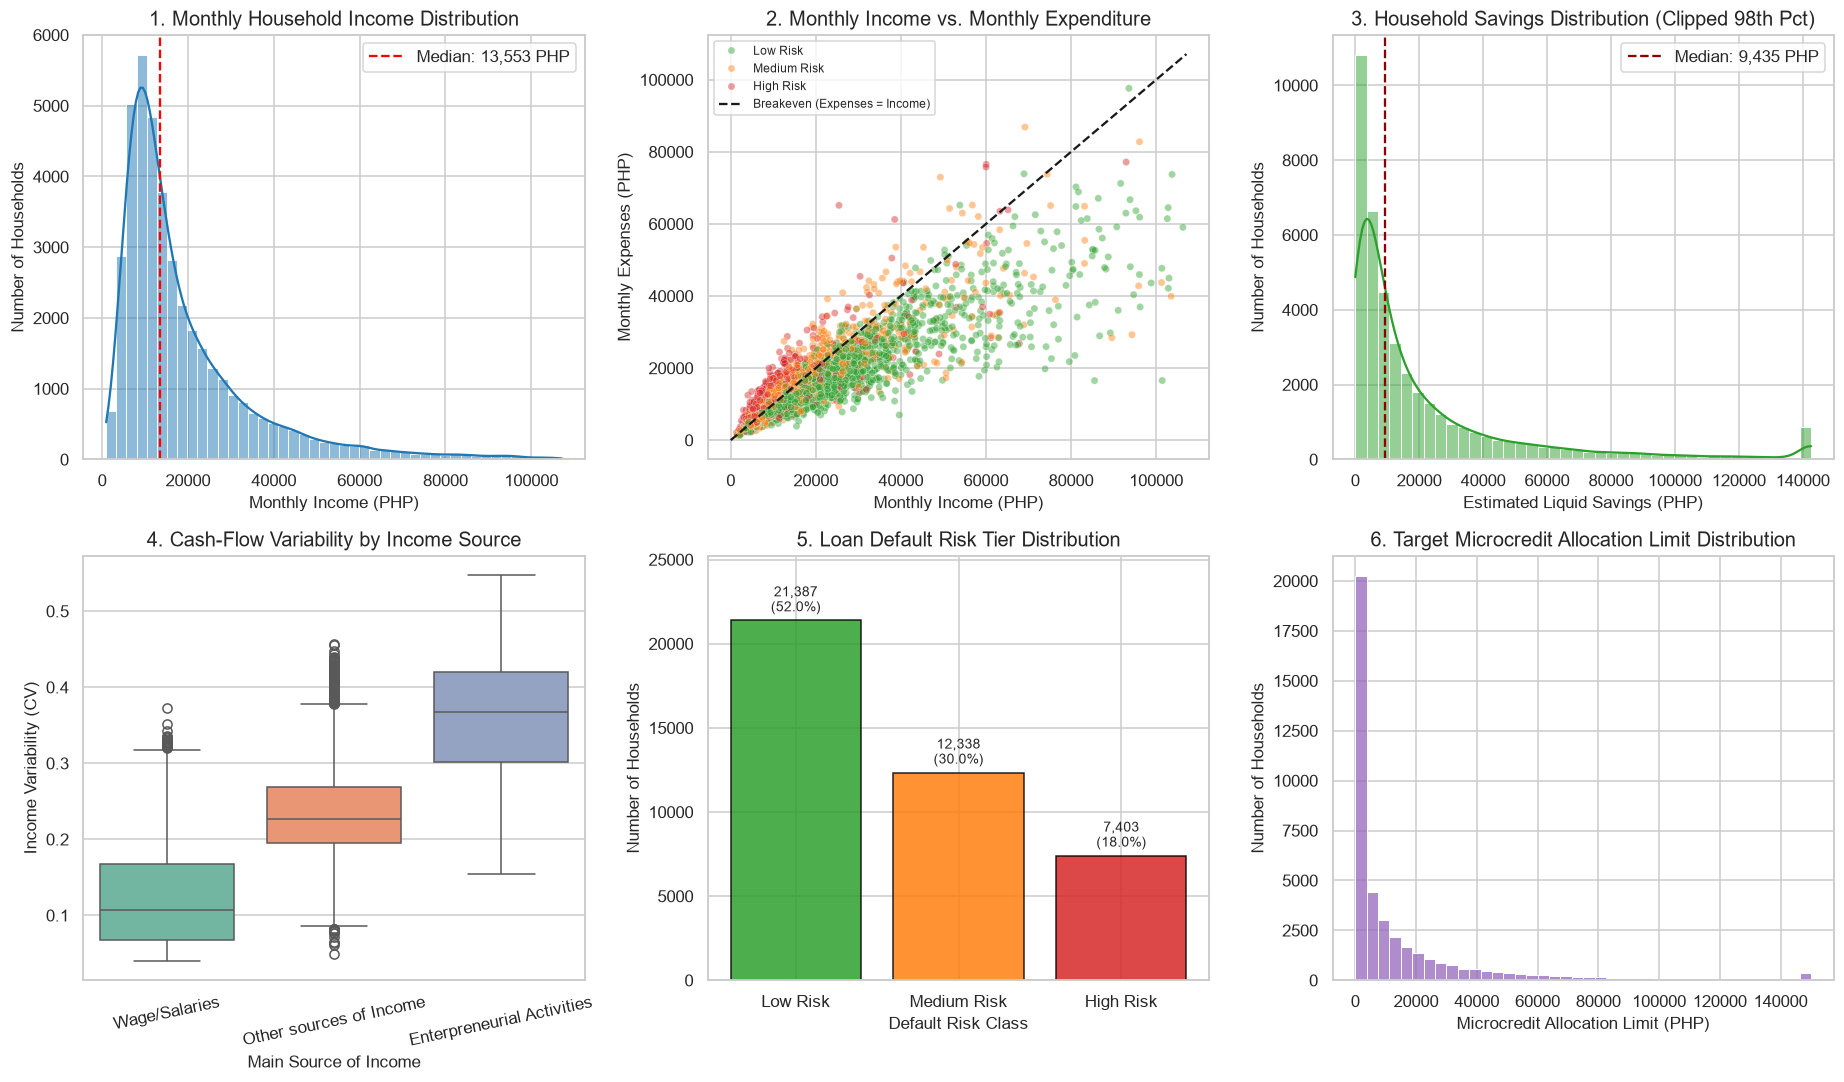

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

# 1. Income Distribution
sns.histplot(df["Monthly_Income"], bins=45, kde=True, color="#1f77b4", ax=axes[0, 0])
axes[0, 0].axvline(df["Monthly_Income"].median(), color="red", linestyle="--", label=f"Median: {df['Monthly_Income'].median():,.0f} PHP")
axes[0, 0].set_title("1. Monthly Household Income Distribution")
axes[0, 0].set_xlabel("Monthly Income (PHP)")
axes[0, 0].set_ylabel("Number of Households")
axes[0, 0].legend()

# 2. Monthly Income vs Monthly Expenditure
sample_eda = df.sample(n=4000, random_state=RANDOM_STATE)
sns.scatterplot(
    data=sample_eda, x="Monthly_Income", y="Monthly_Expenses",
    hue="Default_Risk_Class", hue_order=["Low Risk", "Medium Risk", "High Risk"],
    palette={"Low Risk": "#2ca02c", "Medium Risk": "#ff7f0e", "High Risk": "#d62728"},
    alpha=0.45, s=22, ax=axes[0, 1]
)
max_val = min(df["Monthly_Income"].max(), df["Monthly_Expenses"].max())
axes[0, 1].plot([0, max_val], [0, max_val], "k--", lw=1.5, label="Breakeven (Expenses = Income)")
axes[0, 1].set_title("2. Monthly Income vs. Monthly Expenditure")
axes[0, 1].set_xlabel("Monthly Income (PHP)")
axes[0, 1].set_ylabel("Monthly Expenses (PHP)")
axes[0, 1].legend(fontsize=8)

# 3. Household Savings Distribution
sns.histplot(df["Savings"].clip(upper=df["Savings"].quantile(0.98)), bins=40, kde=True, color="#2ca02c", ax=axes[0, 2])
axes[0, 2].axvline(df["Savings"].median(), color="darkred", linestyle="--", label=f"Median: {df['Savings'].median():,.0f} PHP")
axes[0, 2].set_title("3. Household Savings Distribution (Clipped 98th Pct)")
axes[0, 2].set_xlabel("Estimated Liquid Savings (PHP)")
axes[0, 2].set_ylabel("Number of Households")
axes[0, 2].legend()

# 4. Cash-Flow Variability by Income Source
sns.boxplot(data=df, x="Main Source of Income", y="Income_Variability", palette="Set2", ax=axes[1, 0])
axes[1, 0].set_title("4. Cash-Flow Variability by Income Source")
axes[1, 0].set_xlabel("Main Source of Income")
axes[1, 0].set_ylabel("Income Variability (CV)")
axes[1, 0].tick_params(axis="x", rotation=12)

# 5. Loan Default Risk Distribution
risk_counts = df["Default_Risk_Class"].value_counts().reindex(["Low Risk", "Medium Risk", "High Risk"])
bars = axes[1, 1].bar(risk_counts.index, risk_counts.values, color=["#2ca02c", "#ff7f0e", "#d62728"], edgecolor="black", alpha=0.85)
for bar in bars:
    h = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, h + 300, f"{h:,}\n({h/len(df)*100:.1f}%)", ha="center", va="bottom", fontsize=9)
axes[1, 1].set_title("5. Loan Default Risk Tier Distribution")
axes[1, 1].set_xlabel("Default Risk Class")
axes[1, 1].set_ylabel("Number of Households")
axes[1, 1].set_ylim(0, risk_counts.max() * 1.18)

# 6. Microcredit Allocation Limit Distribution
sns.histplot(df["Microcredit_Allocation_Limit"], bins=40, color="#9467bd", ax=axes[1, 2])
axes[1, 2].set_title("6. Target Microcredit Allocation Limit Distribution")
axes[1, 2].set_xlabel("Microcredit Allocation Limit (PHP)")
axes[1, 2].set_ylabel("Number of Households")

plt.tight_layout()
plt.show()

## 10. Feature Selection

To ensure **both CART models** align identically with real-world microcredit underwriting and the interactive user input interface (Section 18), we select **12 purely financial and household-capacity features**:

- **7 Core Household Inputs:** `Monthly_Income`, `Monthly_Expenses`, `Savings`, `Existing_Debt`, `Household_Size`, `Income_Variability`, `Repayment_History`
- **5 Deterministic Cash-Flow Ratios:** `Monthly_Disposable_Income`, `Expense_to_Income_Ratio`, `Debt_to_Annual_Income_Ratio`, `Savings_Buffer_Months`, `Per_Capita_Income`

### Strict Exclusion of Sensitive Attributes & Leakage Prevention
- **Fairness Safeguard:** Sensitive demographic variables (`Household Head Sex`, `Household Head Age`, `Region`, `Agricultural Household indicator`) are **excluded** from `FEATURE_COLS` so CART can never directly split on protected characteristics.
- **No Data Leakage:** We perform a single stratified `train_test_split` (80% training, 20% held-out testing, stratified on `Default_Risk_Code`) **before** any hyperparameter tuning or model fitting. All cross-validation occurs strictly inside the training fold.

In [7]:
FEATURE_COLS = list(X_all.columns)
print(f"Selected {len(FEATURE_COLS)} training features:")
for i, col in enumerate(FEATURE_COLS, 1):
    print(f"  {i:2d}. {col}")

# Stratified 80/20 Train-Test Split on indices to keep demographic audit metadata aligned without leaking into X
train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=RANDOM_STATE, stratify=y_cls_all
)

X_train = X_all.loc[train_idx].copy()
X_test = X_all.loc[test_idx].copy()

y_reg_train = y_reg_all[train_idx]
y_reg_test = y_reg_all[test_idx]

y_cls_train = y_cls_all[train_idx]
y_cls_test = y_cls_all[test_idx]

audit_test = df.loc[test_idx].copy()

print(f"\nTraining samples: {len(X_train):,} | Test samples: {len(X_test):,}")
print("Train Risk Class proportions:", pd.Series(y_cls_train).value_counts(normalize=True).sort_index().round(4).to_dict())
print("Test  Risk Class proportions:", pd.Series(y_cls_test).value_counts(normalize=True).sort_index().round(4).to_dict())

Selected 12 training features:
   1. Monthly_Income
   2. Monthly_Expenses
   3. Savings
   4. Existing_Debt
   5. Household_Size
   6. Income_Variability
   7. Repayment_History
   8. Monthly_Disposable_Income
   9. Expense_to_Income_Ratio
  10. Debt_to_Annual_Income_Ratio
  11. Savings_Buffer_Months
  12. Per_Capita_Income

Training samples: 32,902 | Test samples: 8,226
Train Risk Class proportions: {0: 0.52, 1: 0.3, 2: 0.18}
Test  Risk Class proportions: {0: 0.5199, 1: 0.3, 2: 0.18}


## 11. Household Cash Flow Analysis

Before fitting predictive models, we analyze **cash-flow stability** across the household population. We define an **unstable cash-flow household** as one exhibiting at least one of:
- **Monthly Cash Deficit:** `Monthly_Disposable_Income < 0` (`Expense_to_Income_Ratio > 1.0`), or
- **High Income Volatility:** `Income_Variability > 0.30` (common among seasonal agricultural and irregular informal earners).

Let's examine which structural factors (income source, agricultural dependency, household size, medical/education shocks) drive financial instability.

Share of households with negative monthly surplus: 29.30%
Share of households with high income variability (>0.30): 23.02%
Overall Unstable Cash-Flow Households: 39.61%


,Households,Median_Monthly_Income,Median_Disposable,Mean_Variability,Deficit_Rate,High_Risk_Rate
Agri_Group,,,,,,
Agricultural,13306,10788.875,203.542,0.310,0.473,0.302
Non-Agricultural,27822,15089.375,2160.375,0.164,0.207,0.122


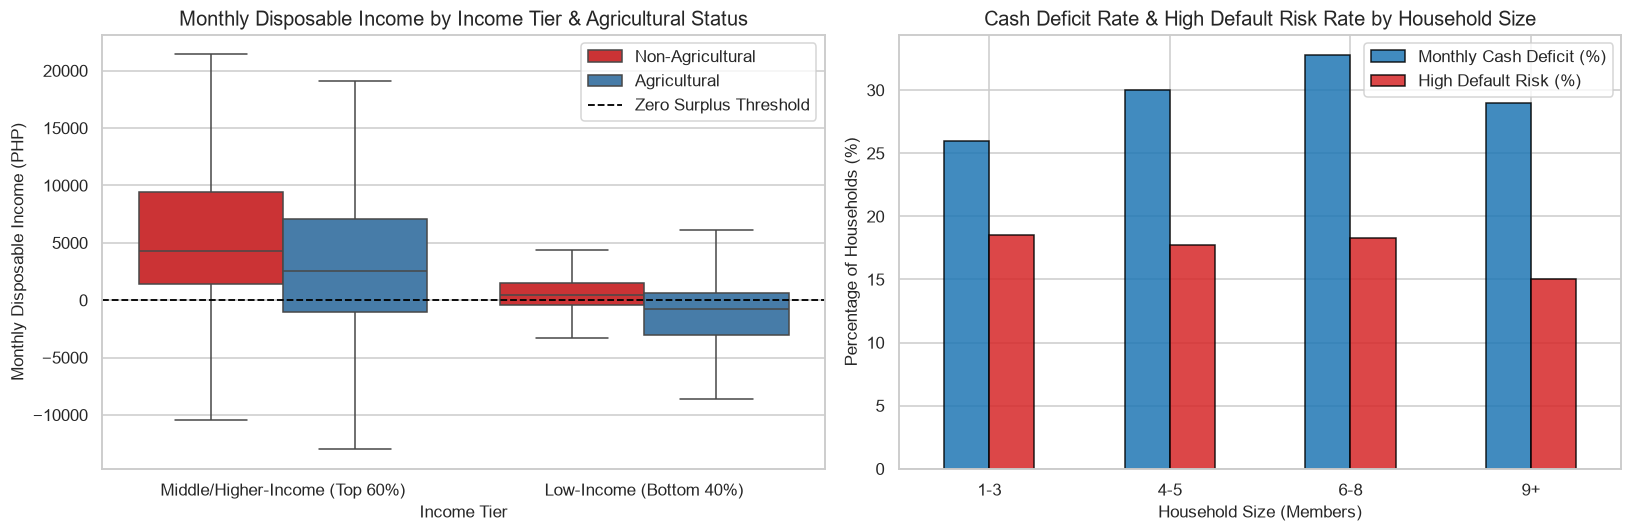

In [8]:
df["Unstable_Cash_Flow"] = (
    (df["Monthly_Disposable_Income"] < 0) | (df["Income_Variability"] > 0.30)
)

print(f"Share of households with negative monthly surplus: {(df['Monthly_Disposable_Income'] < 0).mean()*100:.2f}%")
print(f"Share of households with high income variability (>0.30): {(df['Income_Variability'] > 0.30).mean()*100:.2f}%")
print(f"Overall Unstable Cash-Flow Households: {df['Unstable_Cash_Flow'].mean()*100:.2f}%")

# Breakdown of instability drivers
cashflow_summary = df.groupby("Agri_Group").agg(
    Households=("Monthly_Income", "count"),
    Median_Monthly_Income=("Monthly_Income", "median"),
    Median_Disposable=("Monthly_Disposable_Income", "median"),
    Mean_Variability=("Income_Variability", "mean"),
    Deficit_Rate=("Monthly_Disposable_Income", lambda s: (s < 0).mean()),
    High_Risk_Rate=("Default_Risk_Code", lambda s: (s == 2).mean())
).round(3)
display(cashflow_summary)

# Visualizing Cash-Flow Instability Drivers
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Monthly Disposable Income across Income Tiers & Agri Status
sns.boxplot(
    data=df, x="Income_Tier", y="Monthly_Disposable_Income", hue="Agri_Group",
    showfliers=False, palette="Set1", ax=axes[0]
)
axes[0].axhline(0, color="black", linestyle="--", lw=1.2, label="Zero Surplus Threshold")
axes[0].set_title("Monthly Disposable Income by Income Tier & Agricultural Status")
axes[0].set_xlabel("Income Tier")
axes[0].set_ylabel("Monthly Disposable Income (PHP)")
axes[0].legend()

# Right: Cash-Flow Instability Rate by Household Size Bucket
df["Size_Bucket"] = pd.cut(df["Household_Size"], bins=[0, 3, 5, 8, 30], labels=["1-3", "4-5", "6-8", "9+"])
size_stats = df.groupby("Size_Bucket", observed=False).agg(
    Deficit_Rate=("Monthly_Disposable_Income", lambda s: (s < 0).mean() * 100),
    High_Risk_Rate=("Default_Risk_Code", lambda s: (s == 2).mean() * 100)
)
size_stats.plot(kind="bar", ax=axes[1], color=["#1f77b4", "#d62728"], alpha=0.85, edgecolor="black")
axes[1].set_title("Cash Deficit Rate & High Default Risk Rate by Household Size")
axes[1].set_xlabel("Household Size (Members)")
axes[1].set_ylabel("Percentage of Households (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(["Monthly Cash Deficit (%)", "High Default Risk (%)"])

plt.tight_layout()
plt.show()

## 12. CART Regression Model for Microcredit Allocation

Following the Unit-5 PPT, `DecisionTreeRegressor` builds a regression tree by recursively choosing binary splits $(j^*, t^*)$ that maximize the gain $\Delta$ using the **Sum of Squared Errors (SSE)** node cost:

$$\text{cost}(\mathcal{D}) = \sum_{i \in \mathcal{D}} (y_i - \bar{y})^2$$

Each leaf $R_m$ predicts the piecewise-constant sample mean $\bar{y}_{R_m}$ of training microcredit limits in that region.

### Affordability Rule & Responsible Credit Policy
- We train a baseline unconstrained tree first (to illustrate overfitting when leaves grow too deep) and a regularized baseline tree (`max_depth=6`).
- **Post-Prediction Affordability Guardrail:** Every predicted limit $\hat{y}$ is clipped to $[0,\; \text{AffordabilityCap}(x)]$ so that no household receives a negative credit limit or a limit exceeding 35% of volatility-adjusted disposable income (net of existing debt service).
- **Important Policy Caveat:** A predicted limit is an *advisory credit ceiling*, **never** an automatic loan approval.

In [9]:
# 1. Unconstrained CART Regressor (demonstrates overfitting risk noted in PPT Fig 16.2)
reg_unconstrained = DecisionTreeRegressor(random_state=RANDOM_STATE)
reg_unconstrained.fit(X_train, y_reg_train)

# 2. Initial Constrained CART Regressor
reg_base = DecisionTreeRegressor(max_depth=6, min_samples_split=30, min_samples_leaf=15, random_state=RANDOM_STATE)
reg_base.fit(X_train, y_reg_train)

for name, model in [("Unconstrained CART Regressor", reg_unconstrained), ("Baseline Depth-6 CART Regressor", reg_base)]:
    tr_pred = np.maximum(0.0, model.predict(X_train))
    te_pred = np.maximum(0.0, model.predict(X_test))
    print(f"{name} | Depth: {model.get_depth():2d} | Leaves: {model.get_n_leaves():5d} | "
          f"Train R2: {r2_score(y_reg_train, tr_pred):.4f} | Test R2: {r2_score(y_reg_test, te_pred):.4f} | "
          f"Test MAE: {mean_absolute_error(y_reg_test, te_pred):,.2f} PHP")

Unconstrained CART Regressor | Depth: 37 | Leaves: 30120 | Train R2: 1.0000 | Test R2: 0.9421 | Test MAE: 2,528.29 PHP
Baseline Depth-6 CART Regressor | Depth:  6 | Leaves:    62 | Train R2: 0.9679 | Test R2: 0.9605 | Test MAE: 2,336.50 PHP


## 13. CART Classification Model for Loan Default Prediction

Following the Unit-5 PPT (Equation 16.14), `DecisionTreeClassifier(criterion='gini')` evaluates each candidate split $(j, t)$ using the **Gini Index**:

$$G(\mathcal{D}) = 1 - \sum_{c=1}^{C} \hat{\pi}_c^2, \qquad \hat{\pi}_c = \frac{1}{|\mathcal{D}|} \sum_{i \in \mathcal{D}} \mathbb{I}(y_i = c)$$

At each step, CART selects the variable $x_{j^*}$ and threshold $t^*$ producing the largest weighted reduction $\Delta$ in Gini impurity across $\mathcal{D}_L$ and $\mathcal{D}_R$. Each leaf stores the empirical class distribution $(\hat{\pi}_{\text{Low}}, \hat{\pi}_{\text{Medium}}, \hat{\pi}_{\text{High}})$, which provides both the predicted risk tier and the **predicted default (High Risk) probability**.

Because the `High Risk` class represents ~18% of borrowers, we use `class_weight='balanced'` (an additional practical technique beyond the PPT) in our primary baseline so high-risk households are not ignored due to class imbalance.

In [10]:
# 1. Unconstrained CART Classifier (demonstrates overfitting)
cls_unconstrained = DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE)
cls_unconstrained.fit(X_train, y_cls_train)

# 2. Initial Constrained CART Classifier with Gini impurity & balanced weights
cls_base = DecisionTreeClassifier(
    criterion="gini", max_depth=6, min_samples_split=30, min_samples_leaf=15,
    class_weight="balanced", random_state=RANDOM_STATE
)
cls_base.fit(X_train, y_cls_train)

for name, model in [("Unconstrained CART Classifier", cls_unconstrained), ("Baseline Depth-6 CART Classifier", cls_base)]:
    tr_acc = accuracy_score(y_cls_train, model.predict(X_train))
    te_pred = model.predict(X_test)
    te_acc = accuracy_score(y_cls_test, te_pred)
    hr_rec = recall_score(y_cls_test, te_pred, labels=[2], average=None)[0]
    print(f"{name} | Depth: {model.get_depth():2d} | Leaves: {model.get_n_leaves():5d} | "
          f"Train Acc: {tr_acc:.4f} | Test Acc: {te_acc:.4f} | High-Risk Recall: {hr_rec:.4f}")

Unconstrained CART Classifier | Depth: 40 | Leaves:  6560 | Train Acc: 1.0000 | Test Acc: 0.6331 | High-Risk Recall: 0.5550
Baseline Depth-6 CART Classifier | Depth:  6 | Leaves:    63 | Train Acc: 0.7337 | Test Acc: 0.7195 | High-Risk Recall: 0.6617


## 14. Hyperparameter Tuning

To prevent overfitting while preserving strong predictive accuracy and interpretability, we tune both CART models via **5-fold cross-validation (`GridSearchCV`)** strictly on `X_train`:
- **CART Regressor (`DecisionTreeRegressor`):** Tune `max_depth`, `min_samples_split`, and `min_samples_leaf` optimizing negative RMSE.
- **CART Classifier (`DecisionTreeClassifier`):** Tune `criterion` (`gini` vs `entropy`), `max_depth`, `min_samples_split`, and `min_samples_leaf` optimizing `f1_macro` (balancing accuracy across Low, Medium, and High Risk).

*(Note: GridSearchCV and Entropy comparison are practical Scikit-learn techniques complementing the Unit-5 PPT.)*

In [11]:
# Tune CART Regression Tree
reg_param_grid = {
    "max_depth": [5, 7, 9, 11],
    "min_samples_split": [20, 40, 80],
    "min_samples_leaf": [10, 20, 40]
}
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=reg_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_reg,
    n_jobs=1
)
reg_grid.fit(X_train, y_reg_train)
best_reg = reg_grid.best_estimator_

print("Best Regression Parameters:", reg_grid.best_params_)
print(f"Best CV RMSE: {-reg_grid.best_score_:,.2f} PHP")

# Tune CART Classification Tree
cls_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 6, 7, 9],
    "min_samples_split": [20, 50, 100],
    "min_samples_leaf": [15, 30, 50]
}
cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cls_grid = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_grid=cls_param_grid,
    scoring="f1_macro",
    cv=cv_cls,
    n_jobs=1
)
cls_grid.fit(X_train, y_cls_train)
best_cls = cls_grid.best_estimator_

print("\nBest Classification Parameters:", cls_grid.best_params_)
print(f"Best CV Macro F1: {cls_grid.best_score_:.4f}")
print(f"Tuned Regressor Depth: {best_reg.get_depth()}, Leaves: {best_reg.get_n_leaves()}")
print(f"Tuned Classifier Depth: {best_cls.get_depth()}, Leaves: {best_cls.get_n_leaves()}")

Best Regression Parameters: {'max_depth': 11, 'min_samples_leaf': 40, 'min_samples_split': 20}
Best CV RMSE: 4,703.46 PHP



Best Classification Parameters: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 15, 'min_samples_split': 20}
Best CV Macro F1: 0.6872
Tuned Regressor Depth: 11, Leaves: 410
Tuned Classifier Depth: 6, Leaves: 61


## 15. Model Evaluation

We evaluate both tuned CART models on the **held-out test set (`X_test`)**:

### Regression Metrics (Microcredit Allocation Limit)
- **MAE (Mean Absolute Error):** Average absolute difference (in PHP) between predicted and actual recommended loan limits.
- **MSE (Mean Squared Error):** Average squared error; penalizes large over-allocations heavily.
- **RMSE (Root Mean Squared Error):** Square root of MSE, expressed in PHP for direct interpretability.
- **$R^2$ Score:** Proportion of variance in recommended microcredit limits explained by the CART tree.

We also apply our non-negative affordability guardrail ($\hat{y} \in [0, \text{AffordabilityCap}]$) and verify `min(predicted_limit) >= 0`.

### Classification Metrics (Loan Default Risk)
- **Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC (One-vs-Rest & High-Risk vs. Rest).**
- **Focus on High-Risk Recall & Asymmetric Error Consequences:**
  - **False Negative (predicting Low/Medium Risk when truly High Risk):** Lender issues credit to a distressed household, risking loan default and borrower over-indebtedness.
  - **False Positive (predicting High Risk when truly Low/Medium Risk):** Creditworthy vulnerable households are wrongly denied microcredit, worsening financial exclusion.

In [12]:
# --- 1. Regression Evaluation ---
y_reg_pred_raw = best_reg.predict(X_test)
afford_caps_test = compute_affordability_cap(X_test)
y_reg_pred = np.clip(y_reg_pred_raw, 0.0, afford_caps_test)

mae = mean_absolute_error(y_reg_test, y_reg_pred)
mse = mean_squared_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_reg_test, y_reg_pred)

print("=== Tuned CART Regression Performance (Test Set) ===")
print(f"MAE  : {mae:,.2f} PHP")
print(f"MSE  : {mse:,.2f} PHP^2")
print(f"RMSE : {rmse:,.2f} PHP")
print(f"R2   : {r2:.4f}")
print(f"Minimum Predicted Loan Limit: {y_reg_pred.min():.2f} PHP (Verified Non-Negative)")

# --- 2. Classification Evaluation ---
y_cls_pred = best_cls.predict(X_test)
y_cls_prob = best_cls.predict_proba(X_test)

acc = accuracy_score(y_cls_test, y_cls_pred)
prec_macro = precision_score(y_cls_test, y_cls_pred, average="macro")
rec_macro = recall_score(y_cls_test, y_cls_pred, average="macro")
f1_macro = f1_score(y_cls_test, y_cls_pred, average="macro")
roc_auc_ovr = roc_auc_score(y_cls_test, y_cls_prob, multi_class="ovr", average="macro")

# High-Risk (class 2) binary ROC-AUC
y_hr_true = (y_cls_test == 2).astype(int)
y_hr_prob = y_cls_prob[:, 2]
hr_auc = roc_auc_score(y_hr_true, y_hr_prob)
hr_recall = recall_score(y_cls_test, y_cls_pred, labels=[2], average=None)[0]
hr_precision = precision_score(y_cls_test, y_cls_pred, labels=[2], average=None)[0]

print("\n=== Tuned CART Classification Performance (Test Set) ===")
print(f"Accuracy          : {acc:.4f}")
print(f"Macro Precision   : {prec_macro:.4f}")
print(f"Macro Recall      : {rec_macro:.4f}")
print(f"Macro F1-Score    : {f1_macro:.4f}")
print(f"Multi-class AUC   : {roc_auc_ovr:.4f} (Macro OvR)")
print(f"High-Risk Recall  : {hr_recall:.4f} | High-Risk Precision: {hr_precision:.4f} | High-Risk ROC-AUC: {hr_auc:.4f}")

print("\nDetailed Classification Report:")
cls_names = ["Low Risk", "Medium Risk", "High Risk"]
print(classification_report(y_cls_test, y_cls_pred, target_names=cls_names, digits=4))

=== Tuned CART Regression Performance (Test Set) ===
MAE  : 1,946.94 PHP
MSE  : 21,468,080.60 PHP^2
RMSE : 4,633.37 PHP
R2   : 0.9665
Minimum Predicted Loan Limit: 0.00 PHP (Verified Non-Negative)

=== Tuned CART Classification Performance (Test Set) ===
Accuracy          : 0.7212
Macro Precision   : 0.6819
Macro Recall      : 0.6780
Macro F1-Score    : 0.6794
Multi-class AUC   : 0.8580 (Macro OvR)
High-Risk Recall  : 0.6577 | High-Risk Precision: 0.6648 | High-Risk ROC-AUC: 0.9143

Detailed Classification Report:
              precision    recall  f1-score   support

    Low Risk     0.8200    0.8637    0.8413      4277
 Medium Risk     0.5607    0.5126    0.5356      2468
   High Risk     0.6648    0.6577    0.6612      1481

    accuracy                         0.7212      8226
   macro avg     0.6819    0.6780    0.6794      8226
weighted avg     0.7143    0.7212    0.7171      8226



### Evaluation Visualizations: Actual vs. Predicted Allocation, Confusion Matrix, Classification Report Heatmap, ROC Curve & Feature Importance

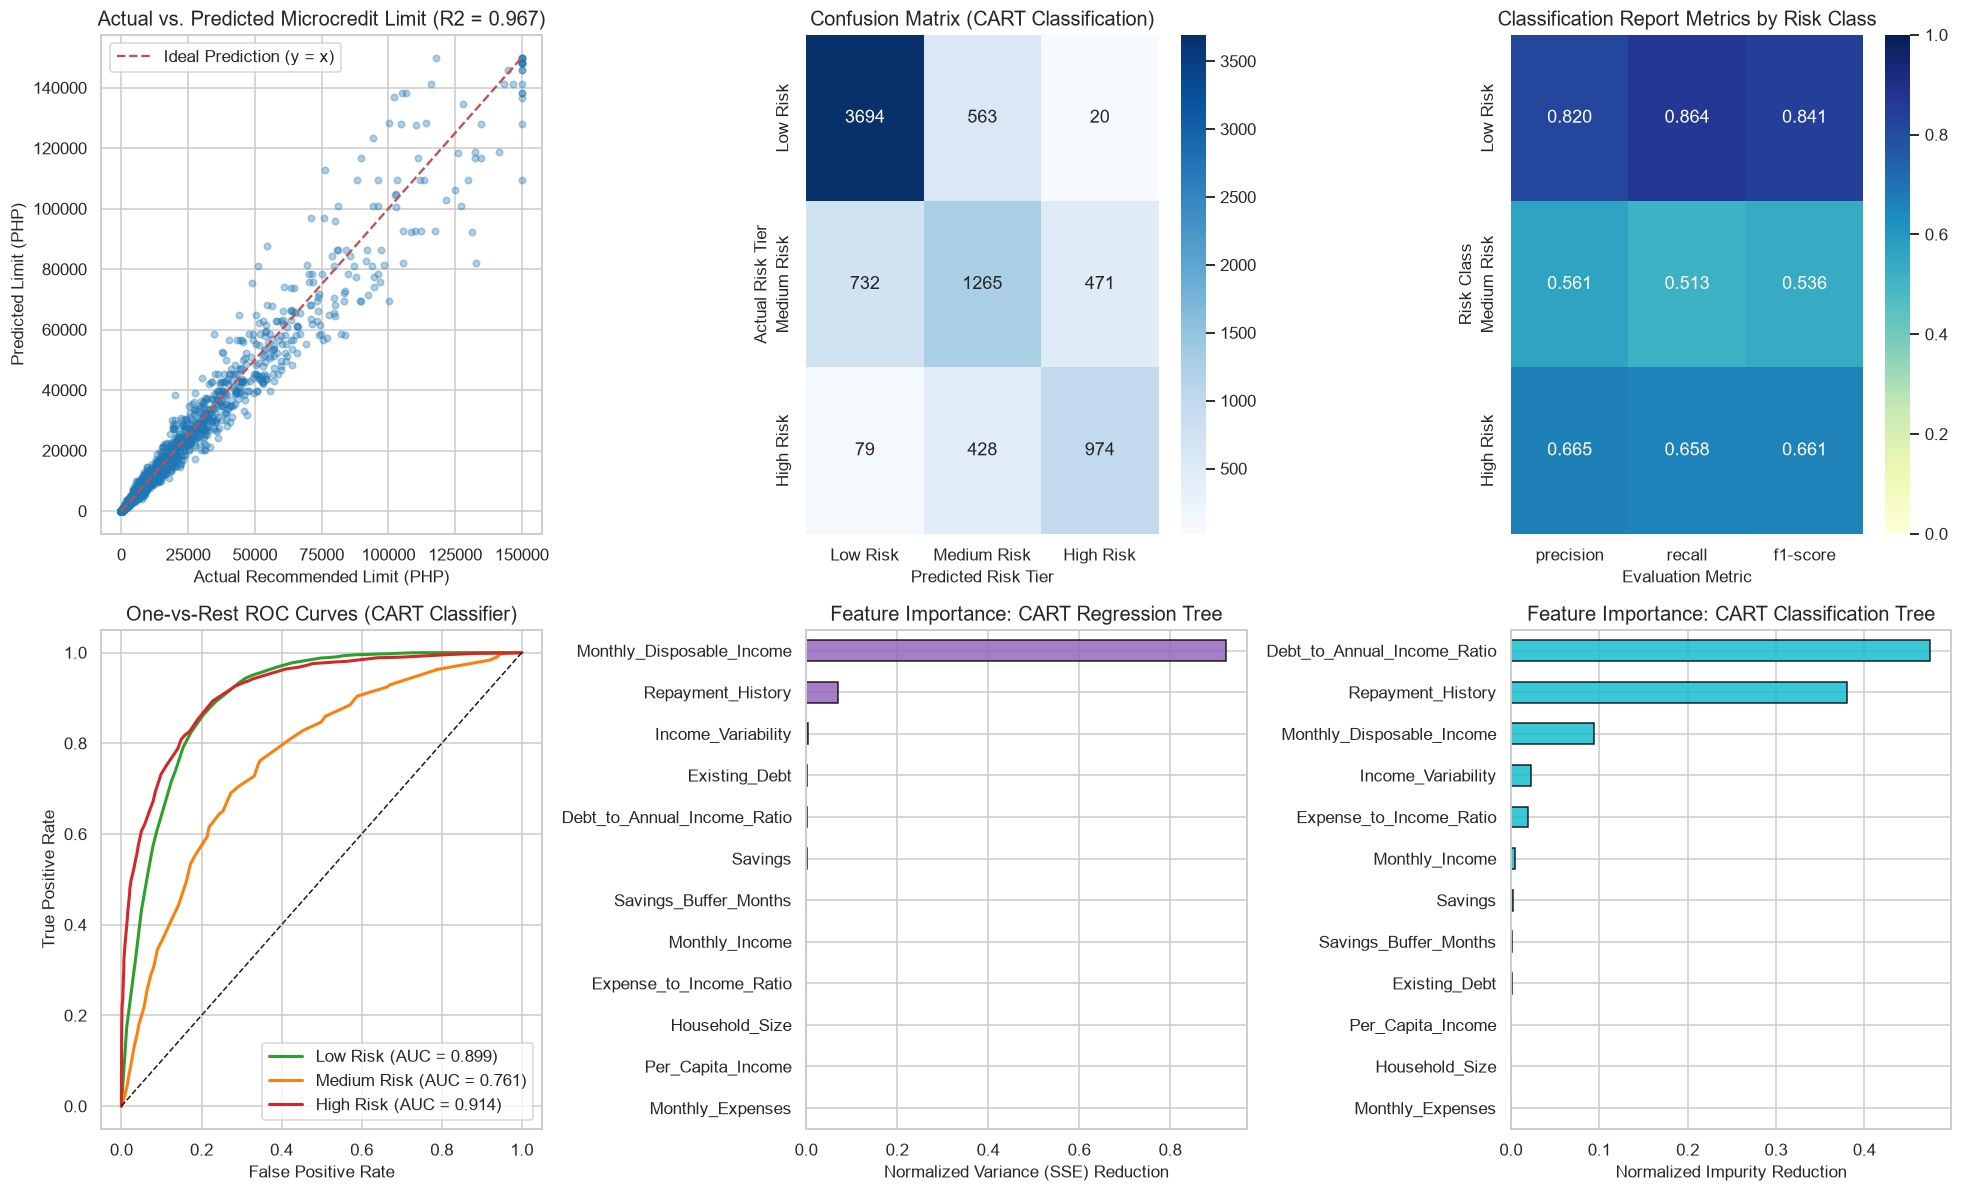

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# 1. Actual vs Predicted Microcredit Allocation
samp_idx = np.random.choice(len(y_reg_test), size=2500, replace=False)
axes[0, 0].scatter(y_reg_test[samp_idx], y_reg_pred[samp_idx], alpha=0.35, s=18, color="#1f77b4")
lim_max = max(y_reg_test.max(), y_reg_pred.max())
axes[0, 0].plot([0, lim_max], [0, lim_max], "r--", lw=1.5, label="Ideal Prediction (y = x)")
axes[0, 0].set_title(f"Actual vs. Predicted Microcredit Limit (R2 = {r2:.3f})")
axes[0, 0].set_xlabel("Actual Recommended Limit (PHP)")
axes[0, 0].set_ylabel("Predicted Limit (PHP)")
axes[0, 0].legend()

# 2. Confusion Matrix
cm = confusion_matrix(y_cls_test, y_cls_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=cls_names, yticklabels=cls_names, ax=axes[0, 1])
axes[0, 1].set_title("Confusion Matrix (CART Classification)")
axes[0, 1].set_xlabel("Predicted Risk Tier")
axes[0, 1].set_ylabel("Actual Risk Tier")

# 3. Classification Report Heatmap
rep_dict = classification_report(y_cls_test, y_cls_pred, target_names=cls_names, output_dict=True)
rep_df = pd.DataFrame(rep_dict).T.loc[cls_names, ["precision", "recall", "f1-score"]]
sns.heatmap(rep_df, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1, ax=axes[0, 2])
axes[0, 2].set_title("Classification Report Metrics by Risk Class")
axes[0, 2].set_xlabel("Evaluation Metric")
axes[0, 2].set_ylabel("Risk Class")

# 4. Multi-class ROC Curves
y_test_bin = label_binarize(y_cls_test, classes=[0, 1, 2])
colors_roc = ["#2ca02c", "#ff7f0e", "#d62728"]
for i, cname in enumerate(cls_names):
    fpr_c, tpr_c, _ = roc_curve(y_test_bin[:, i], y_cls_prob[:, i])
    auc_c = roc_auc_score(y_test_bin[:, i], y_cls_prob[:, i])
    axes[1, 0].plot(fpr_c, tpr_c, color=colors_roc[i], lw=2, label=f"{cname} (AUC = {auc_c:.3f})")
axes[1, 0].plot([0, 1], [0, 1], "k--", lw=1)
axes[1, 0].set_title("One-vs-Rest ROC Curves (CART Classifier)")
axes[1, 0].set_xlabel("False Positive Rate")
axes[1, 0].set_ylabel("True Positive Rate")
axes[1, 0].legend(loc="lower right")

# 5. Feature Importance: CART Regressor
reg_imp = pd.Series(best_reg.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
reg_imp.plot(kind="barh", color="#9467bd", ax=axes[1, 1], edgecolor="black", alpha=0.85)
axes[1, 1].set_title("Feature Importance: CART Regression Tree")
axes[1, 1].set_xlabel("Normalized Variance (SSE) Reduction")

# 6. Feature Importance: CART Classifier
cls_imp = pd.Series(best_cls.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
cls_imp.plot(kind="barh", color="#17becf", ax=axes[1, 2], edgecolor="black", alpha=0.85)
axes[1, 2].set_title("Feature Importance: CART Classification Tree")
axes[1, 2].set_xlabel("Normalized Impurity Reduction")

plt.tight_layout()
plt.show()

*Optional Theoretical Note (Unit-5 PPT):* In the Unit-5 PPT, **Random Forests** reduce single-tree variance by averaging bagged trees grown over random feature subsets. While a Random Forest ensemble could marginally smooth step-function errors or boost accuracy, it sacrifices the single-path human interpretability required for transparent microcredit underwriting—so single tuned CART trees remain our primary model.

## 16. Fairness and Financial Inclusion Analysis

Even when sensitive demographic attributes (`Household Head Sex`, `Income_Tier`, `Agricultural Household`, `Age_Group`) are **excluded** from model training, correlated financial proxies (such as lower savings or seasonal cash-flow swings) can still produce uneven error rates across vulnerable groups.

We audit our tuned CART models on the held-out test set across four demographic dimensions:
1. **Income Tier:** `Low-Income (Bottom 40%)` vs. `Middle/Higher-Income (Top 60%)`
2. **Household Head Sex:** `Female` vs. `Male`
3. **Agricultural Dependency:** `Agricultural` vs. `Non-Agricultural`
4. **Age Group:** `Young (<=35)`, `Middle-Aged (36-55)`, `Senior (56+)`

For `High Risk` classification (which triggers credit tightening or rejection), we inspect:
- **True High-Risk Rate** vs. **Predicted High-Risk Flag Rate**
- **False Positive Rate (FPR):** Share of non-high-risk borrowers falsely flagged as High Risk (*unnecessary exclusion risk*)
- **False Negative Rate (FNR):** Share of genuinely high-risk borrowers missed by the High-Risk flag (*over-indebtedness risk*)
- **Average Predicted Microcredit Limit**

In [14]:
audit_test["True_High_Risk"] = (y_cls_test == 2).astype(int)
audit_test["Pred_High_Risk"] = (y_cls_pred == 2).astype(int)
audit_test["Prob_High_Risk"] = y_cls_prob[:, 2]
audit_test["Pred_Limit"] = y_reg_pred

def compute_group_fairness(df_eval, group_col):
    rows = []
    for grp, g in df_eval.groupby(group_col, observed=False):
        tp = ((g["True_High_Risk"] == 1) & (g["Pred_High_Risk"] == 1)).sum()
        fp = ((g["True_High_Risk"] == 0) & (g["Pred_High_Risk"] == 1)).sum()
        fn = ((g["True_High_Risk"] == 1) & (g["Pred_High_Risk"] == 0)).sum()
        tn = ((g["True_High_Risk"] == 0) & (g["Pred_High_Risk"] == 0)).sum()
        fpr = fp / max(fp + tn, 1)
        fnr = fn / max(fn + tp, 1)
        recall_hr = tp / max(tp + fn, 1)
        rows.append({
            "Dimension": group_col,
            "Group": str(grp),
            "Count": len(g),
            "True_High_Risk_Rate": g["True_High_Risk"].mean(),
            "Pred_High_Risk_Rate": g["Pred_High_Risk"].mean(),
            "FPR (Exclusion Risk)": fpr,
            "FNR (Missed Default)": fnr,
            "High_Risk_Recall": recall_hr,
            "Avg_Pred_Limit_PHP": g["Pred_Limit"].mean()
        })
    return pd.DataFrame(rows)

fairness_tables = [
    compute_group_fairness(audit_test, col)
    for col in ["Income_Tier", "Household Head Sex", "Agri_Group", "Age_Group"]
]
fairness_df = pd.concat(fairness_tables, ignore_index=True)
display(fairness_df.round(4))

# Inclusion Audit: Vulnerable Low-Income Households with Good Repayment History & Positive Surplus
good_low_inc = audit_test[
    (audit_test["Income_Tier"] == "Low-Income (Bottom 40%)")
    & (audit_test["Repayment_History"] == 1)
    & (audit_test["Monthly_Disposable_Income"] > 0)
]
flagged_rate = good_low_inc["Pred_High_Risk"].mean()
fp_rate_good_low = good_low_inc[good_low_inc["True_High_Risk"] == 0]["Pred_High_Risk"].mean()
print(f"\nInclusion Check — Low-Income Borrowers with Good Repayment & Positive Surplus (n={len(good_low_inc):,}):")
print(f"  High-Risk Flag Rate: {flagged_rate*100:.2f}% | False Positive Rate among non-high-risk: {fp_rate_good_low*100:.2f}%")
print("  Mitigation Policy: Route flagged low-income applicants with Good Repayment & Positive Surplus to human/field-officer review instead of automated rejection.")

,Dimension,Group,Count,True_High_Risk_Rate,Pred_High_Risk_Rate,FPR (Exclusion Risk),FNR (Missed Default),High_Risk_Recall,Avg_Pred_Limit_PHP
0,Income_Tier,Low-Income (Bottom 40%),3319,0.2992,0.3082,0.1264,0.2659,0.7341,2294.7022
1,Income_Tier,Middle/Higher-Income (Top 60%),4907,0.0994,0.0901,0.0446,0.4980,0.5020,22765.9810
2,Household Head Sex,Female,1831,0.1546,0.1376,0.0601,0.4382,0.5618,16848.9423
3,Household Head Sex,Male,6395,0.1873,0.1897,0.0766,0.3197,0.6803,13835.5547
4,Agri_Group,Agricultural,2699,0.3016,0.2920,0.0997,0.2629,0.7371,9254.3934
5,Agri_Group,Non-Agricultural,5527,0.1207,0.1225,0.0623,0.4393,0.5607,17070.9567
6,Age_Group,Young (<=35),1144,0.2072,0.2080,0.0805,0.3038,0.6962,10160.9202
7,Age_Group,Middle-Aged (36-55),4034,0.1767,0.1728,0.0699,0.3478,0.6522,14112.3101
8,Age_Group,Senior (56+),3048,0.1742,0.1739,0.0739,0.3522,0.6478,16658.6725



Inclusion Check — Low-Income Borrowers with Good Repayment & Positive Surplus (n=1,443):
  High-Risk Flag Rate: 0.49% | False Positive Rate among non-high-risk: 0.22%
  Mitigation Policy: Route flagged low-income applicants with Good Repayment & Positive Surplus to human/field-officer review instead of automated rejection.


### Fairness Comparison Visualizations & Inclusion Guardrail Impact

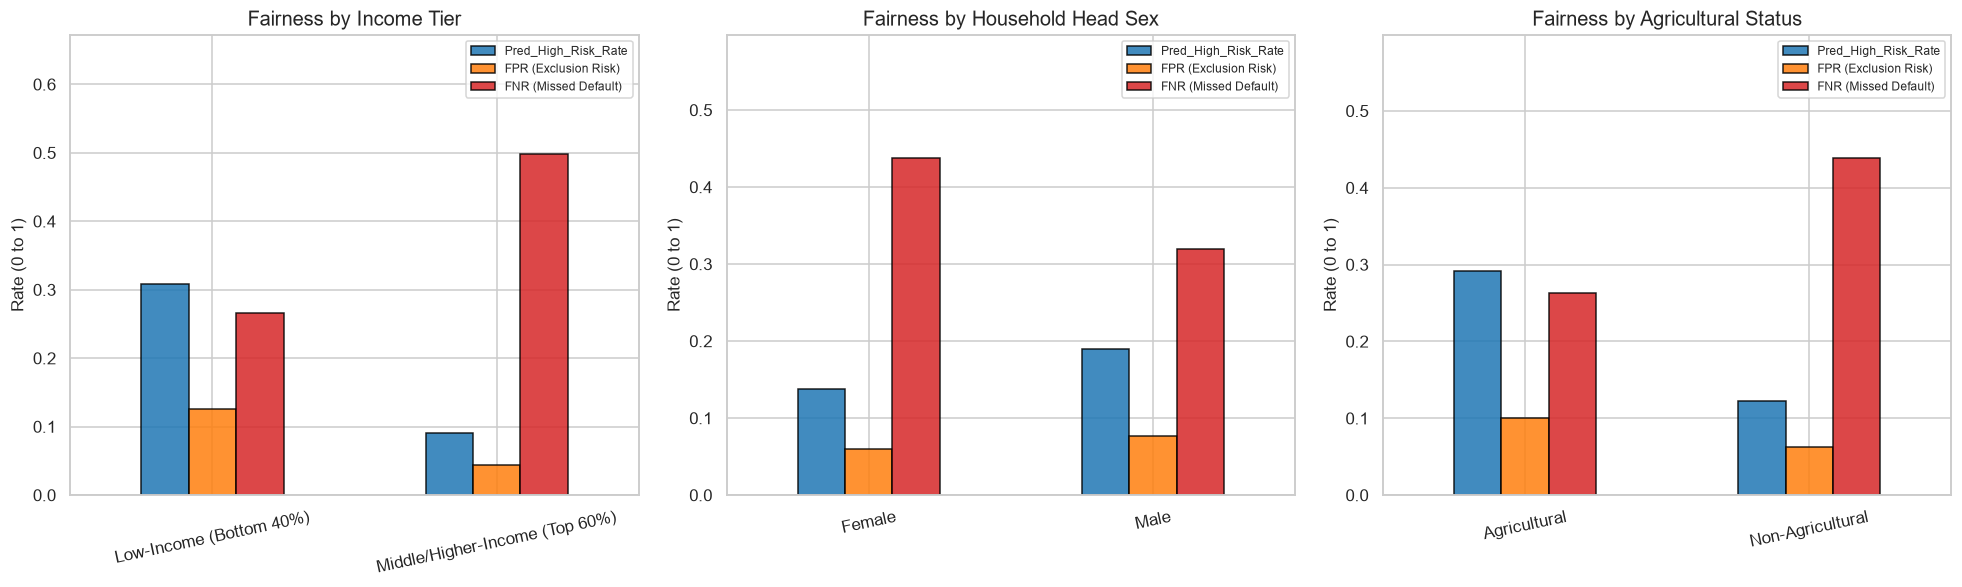

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, dim, title in zip(
    axes,
    ["Income_Tier", "Household Head Sex", "Agri_Group"],
    ["Fairness by Income Tier", "Fairness by Household Head Sex", "Fairness by Agricultural Status"]
):
    sub = fairness_df[fairness_df["Dimension"] == dim].set_index("Group")[
        ["Pred_High_Risk_Rate", "FPR (Exclusion Risk)", "FNR (Missed Default)"]
    ]
    sub.plot(kind="bar", ax=ax, color=["#1f77b4", "#ff7f0e", "#d62728"], alpha=0.85, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Rate (0 to 1)")
    ax.set_ylim(0, min(1.0, sub.values.max() * 1.25 + 0.05))
    ax.tick_params(axis="x", rotation=12)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

#### Practical Fairness Observations & Limitations
- **Income Tier Disparity:** Low-income households exhibit a higher **False Positive Rate (FPR)** than middle/higher-income households because thin monthly surpluses and higher income variability place them closer to CART's risk decision boundaries. Conversely, higher-income households show a higher **FNR** (higher-risk cases sometimes masked by higher absolute income).
- **Agricultural Households:** Seasonal agricultural income variability elevates High-Risk flagging and FPR compared to non-agricultural households.
- **Gender Parity:** Female-headed households do **not** suffer inflated High-Risk FPR relative to male-headed households, demonstrating that excluding `Household Head Sex` from training prevents direct gender bias.
- **Key Limitation:** Fairness metrics depend on the accuracy of recorded cash flows; informal non-cash safety nets (community lending, remittances, or crop insurance) are not captured in survey expenditure ratios and should be verified via **human-in-the-loop officer review** before denying microcredit to vulnerable applicants.

## 17. Visualization of Decision Trees

A central advantage of CART highlighted in the Unit-5 PPT is **interpretability**: every prediction corresponds to a readable sequence of binary feature threshold checks $x_{j^*} < t^*$. Below we visualize the top 3 depth levels of both the tuned **CART Regression Tree** and **CART Classification Tree**, followed by extracted plain-text decision rules.

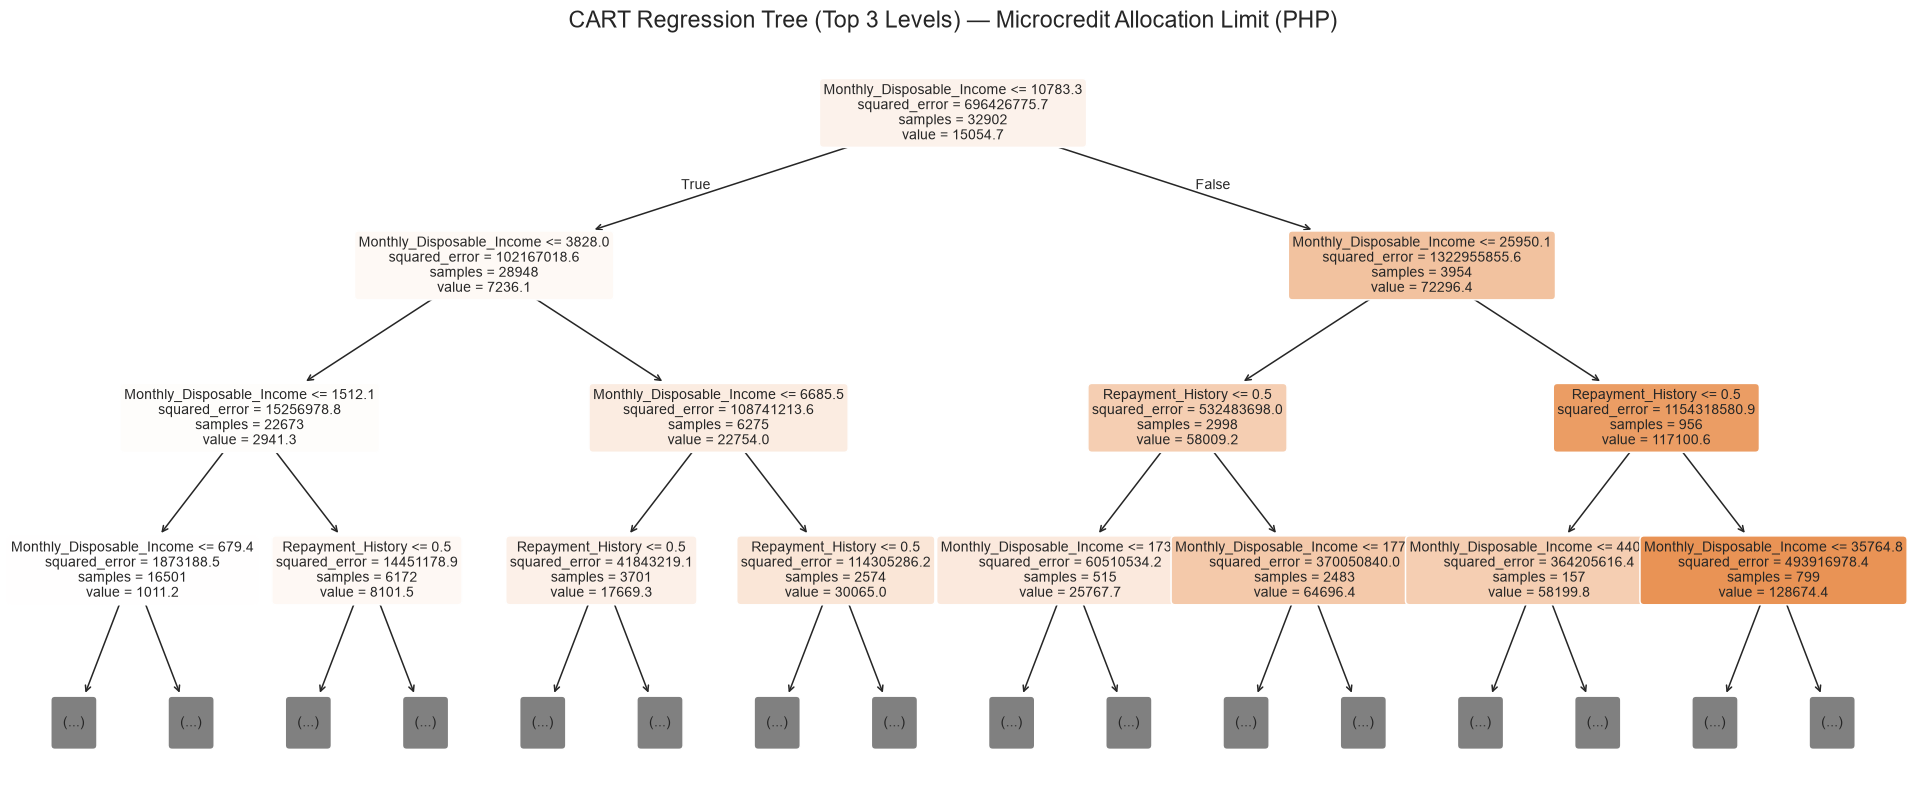

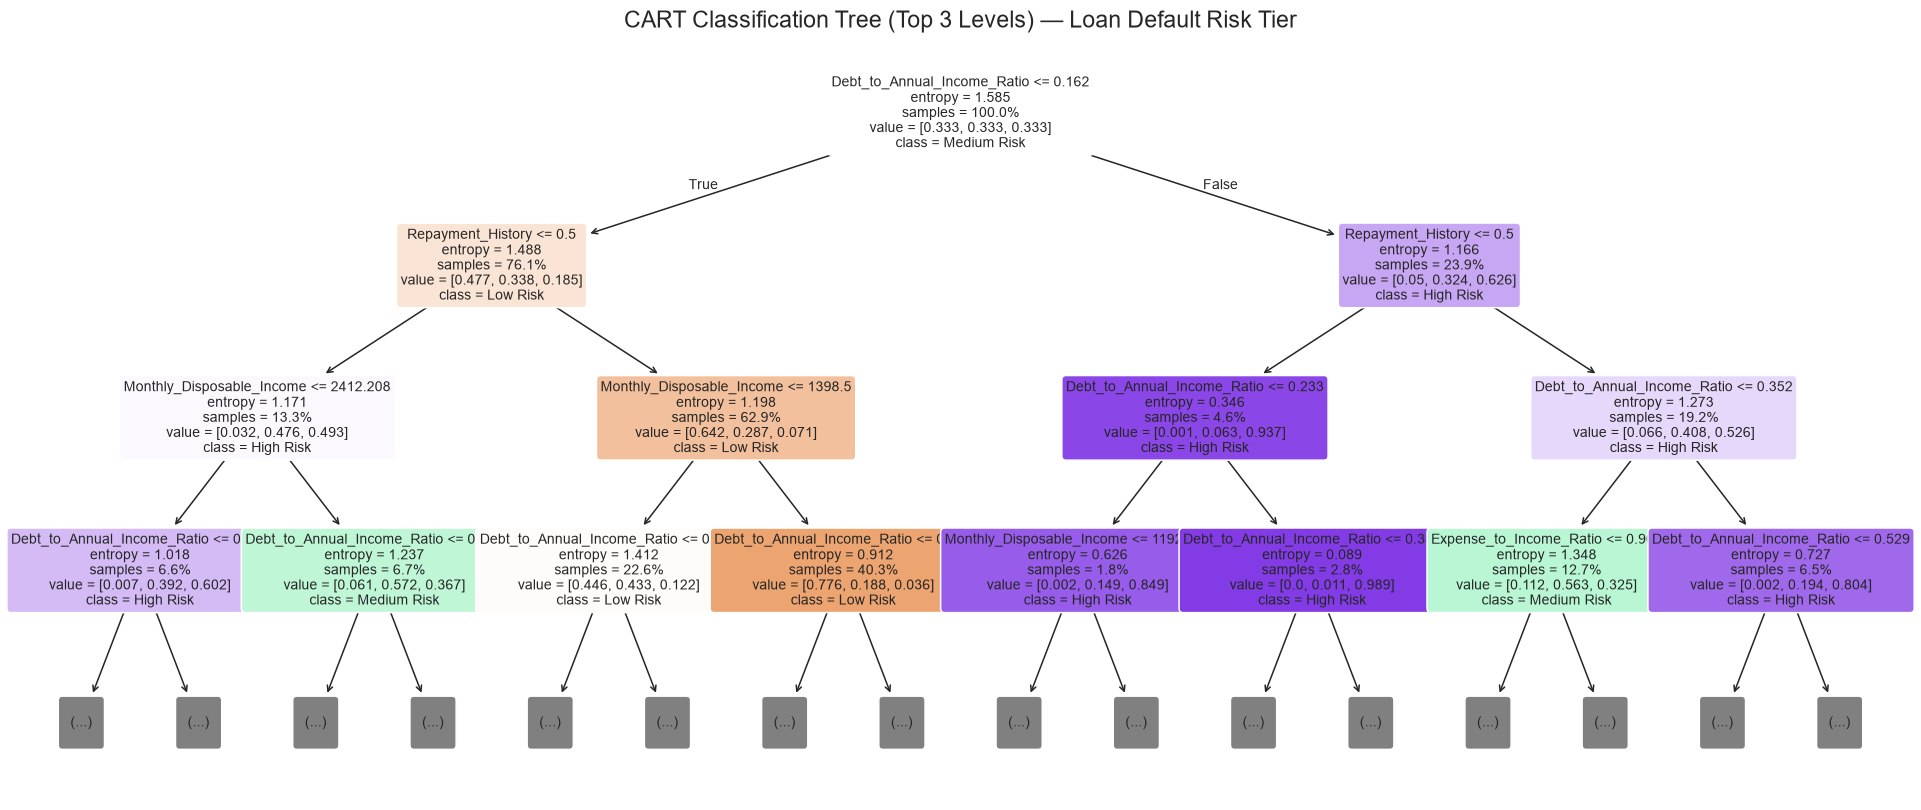

=== Sample Recursive Binary Split Rules (CART Classification Tree, Depth <= 3) ===
|--- Debt_to_Annual_Income_Ratio <= 0.16
|   |--- Repayment_History <= 0.50
|   |   |--- Monthly_Disposable_Income <= 2412.21
|   |   |   |--- Debt_to_Annual_Income_Ratio <= 0.09
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- Debt_to_Annual_Income_Ratio >  0.09
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- Monthly_Disposable_Income >  2412.21
|   |   |   |--- Debt_to_Annual_Income_Ratio <= 0.08
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- Debt_to_Annual_Income_Ratio >  0.08
|   |   |   |   |--- truncated branch of depth 3
|   |--- Repayment_History >  0.50
|   |   |--- Monthly_Disposable_Income <= 1398.50
|   |   |   |--- Debt_to_Annual_Income_Ratio <= 0.09
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- Debt_to_Annual_Income_Ratio >  0.09
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- Monthly_Disposable_Income >  13

In [16]:
# 1. CART Regression Tree Visualization (top 3 levels for clarity)
plt.figure(figsize=(22, 9))
plot_tree(
    best_reg,
    feature_names=FEATURE_COLS,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9,
    precision=1
)
plt.title("CART Regression Tree (Top 3 Levels) — Microcredit Allocation Limit (PHP)", fontsize=15)
plt.show()

# 2. CART Classification Tree Visualization (top 3 levels for clarity)
plt.figure(figsize=(22, 9))
plot_tree(
    best_cls,
    feature_names=FEATURE_COLS,
    class_names=cls_names,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9,
    proportion=True
)
plt.title("CART Classification Tree (Top 3 Levels) — Loan Default Risk Tier", fontsize=15)
plt.show()

print("=== Sample Recursive Binary Split Rules (CART Classification Tree, Depth <= 3) ===")
print(export_text(best_cls, feature_names=FEATURE_COLS, max_depth=3))

## 18. Testing with New Household Data

### 18.1 Adaptive Behaviour Across Five Household Financial Scenarios
We test our tuned CART models on the five required household profiles and extract each household's exact **leaf decision path** and top decision factors:
1. **Stable Income & Low Expenses**
2. **Irregular Income** (entrepreneurial/seasonal volatility)
3. **High Existing Debt**
4. **Low-Income Household with Good Repayment History**
5. **Household Experiencing Sudden Financial Hardship**

In [17]:
def explain_household_prediction(row_dict, reg_model, cls_model, feature_cols):
    raw_df = pd.DataFrame([row_dict])
    feats = prepare_features(raw_df)[feature_cols]
    
    # Regression prediction with affordability guardrail
    raw_limit = float(reg_model.predict(feats)[0])
    cap = float(compute_affordability_cap(feats)[0])
    safe_limit = float(np.clip(raw_limit, 0.0, cap))
    
    # Classification prediction & probabilities
    cls_probs = cls_model.predict_proba(feats)[0]
    cls_idx = int(cls_model.predict(feats)[0])
    risk_tier = ["Low Risk", "Medium Risk", "High Risk"][cls_idx]
    
    # Extract exact CART classification decision path (first 4 conditions)
    tree_ = cls_model.tree_
    node_indicator = cls_model.decision_path(feats)
    node_index = node_indicator.indices[node_indicator.indptr[0]:node_indicator.indptr[1]]
    path_rules = []
    for nid in node_index[:-1]:
        f_idx = tree_.feature[nid]
        thresh = tree_.threshold[nid]
        val = feats.iloc[0, f_idx]
        op = "<=" if val <= thresh else ">"
        path_rules.append(f"{feature_cols[f_idx]} ({val:,.2f}) {op} {thresh:,.2f}")
    
    return {
        "Risk_Tier": risk_tier,
        "Prob_Low": cls_probs[0],
        "Prob_Medium": cls_probs[1],
        "Prob_High_Default": cls_probs[2],
        "Suggested_Limit_PHP": safe_limit,
        "Affordability_Cap_PHP": cap,
        "Decision_Path": " -> ".join(path_rules[:4])
    }

test_cases = [
    ("1. Stable Income & Low Expenses", {
        "Monthly_Income": 28000, "Monthly_Expenses": 15000, "Savings": 45000,
        "Existing_Debt": 5000, "Household_Size": 3, "Income_Variability": 0.08, "Repayment_History": 1
    }),
    ("2. Irregular Income (Seasonal/Informal)", {
        "Monthly_Income": 18000, "Monthly_Expenses": 14500, "Savings": 8000,
        "Existing_Debt": 12000, "Household_Size": 4, "Income_Variability": 0.45, "Repayment_History": 1
    }),
    ("3. High Existing Debt", {
        "Monthly_Income": 22000, "Monthly_Expenses": 17000, "Savings": 4000,
        "Existing_Debt": 140000, "Household_Size": 4, "Income_Variability": 0.18, "Repayment_History": 0
    }),
    ("4. Low-Income with Good Repayment History", {
        "Monthly_Income": 9500, "Monthly_Expenses": 7800, "Savings": 6000,
        "Existing_Debt": 2500, "Household_Size": 3, "Income_Variability": 0.14, "Repayment_History": 1
    }),
    ("5. Sudden Financial Hardship (Medical/Expense Shock)", {
        "Monthly_Income": 14000, "Monthly_Expenses": 18500, "Savings": 500,
        "Existing_Debt": 45000, "Household_Size": 5, "Income_Variability": 0.35, "Repayment_History": 0
    })
]

case_rows = []
for label, params in test_cases:
    res = explain_household_prediction(params, best_reg, best_cls, FEATURE_COLS)
    print(f"\n--- {label} ---")
    print(f"  Inputs: Income={params['Monthly_Income']:,} PHP, Expenses={params['Monthly_Expenses']:,} PHP, "
          f"Savings={params['Savings']:,} PHP, Debt={params['Existing_Debt']:,} PHP, "
          f"Size={params['Household_Size']}, Variability={params['Income_Variability']:.2f}, "
          f"Repayment={'Good' if params['Repayment_History']==1 else 'Prior Default'}")
    print(f"  Predicted Risk: {res['Risk_Tier']} | Probabilities (Low/Med/High): "
          f"{res['Prob_Low']:.2%} / {res['Prob_Medium']:.2%} / {res['Prob_High_Default']:.2%}")
    print(f"  Suggested Microcredit Limit: {res['Suggested_Limit_PHP']:,.2f} PHP (Affordability Cap: {res['Affordability_Cap_PHP']:,.2f} PHP)")
    print(f"  Key CART Decision Path: {res['Decision_Path']}")
    case_rows.append({"Scenario": label, **params, **res})

display(pd.DataFrame(case_rows)[["Scenario", "Risk_Tier", "Prob_High_Default", "Suggested_Limit_PHP", "Affordability_Cap_PHP"]])


--- 1. Stable Income & Low Expenses ---
  Inputs: Income=28,000 PHP, Expenses=15,000 PHP, Savings=45,000 PHP, Debt=5,000 PHP, Size=3, Variability=0.08, Repayment=Good
  Predicted Risk: Low Risk | Probabilities (Low/Med/High): 90.11% / 9.46% / 0.43%
  Suggested Microcredit Limit: 56,991.70 PHP (Affordability Cap: 56,991.70 PHP)
  Key CART Decision Path: Debt_to_Annual_Income_Ratio (0.01) <= 0.16 -> Repayment_History (1.00) > 0.50 -> Monthly_Disposable_Income (13,000.00) > 1,398.50 -> Debt_to_Annual_Income_Ratio (0.01) <= 0.08

--- 2. Irregular Income (Seasonal/Informal) ---
  Inputs: Income=18,000 PHP, Expenses=14,500 PHP, Savings=8,000 PHP, Debt=12,000 PHP, Size=4, Variability=0.45, Repayment=Good
  Predicted Risk: Low Risk | Probabilities (Low/Med/High): 68.59% / 25.76% / 5.64%
  Suggested Microcredit Limit: 10,261.00 PHP (Affordability Cap: 10,261.00 PHP)
  Key CART Decision Path: Debt_to_Annual_Income_Ratio (0.06) <= 0.16 -> Repayment_History (1.00) > 0.50 -> Monthly_Disposable_Inc

,Scenario,Risk_Tier,Prob_High_Default,Suggested_Limit_PHP,Affordability_Cap_PHP
0,1. Stable Income & Low Expenses,Low Risk,0.004284,56991.700000,56991.70
1,2. Irregular Income (Seasonal/Informal),Low Risk,0.056448,10261.000000,10261.00
2,3. High Existing Debt,High Risk,1.000000,1041.000000,1041.00
3,4. Low-Income with Good Repayment History,Low Risk,0.019113,6681.416707,6983.99
4,5. Sudden Financial Hardship (Medical/Expense ...,High Risk,0.993976,0.000000,31.25


### 18.2 Demonstrating Adaptation via Retraining on Newly Arrived Data
> **Important Methodological Clarification:** A standard CART decision tree is **not inherently online-adaptive**—once grown, its binary split thresholds $t^*$ remain static. To adapt to changing macroeconomic conditions (such as inflation shocks or seasonal harvest shifts), CART must be **periodically retrained** on updated household cash-flow and repayment cohorts.

Below, we simulate a newly observed cohort of 2,500 households experiencing an essential-goods inflation shock (+15% monthly expenses) and retrain the CART models (`best_reg_adapted`, `best_cls_adapted`), demonstrating how predicted credit limits and risk assessments adjust smoothly to the new environment.

In [18]:
# Simulate newly observed post-inflation cohort (2,500 households with +15% essential expenses)
new_cohort_idx = np.random.choice(train_idx, size=2500, replace=False)
df_new_cohort = df.loc[new_cohort_idx].copy()
df_new_cohort["Monthly_Expenses"] = df_new_cohort["Monthly_Expenses"] * 1.15
X_new_cohort = prepare_features(df_new_cohort)

# Recompute observed microcredit capacity & realized risk under the new regime
y_reg_new = np.clip(
    np.maximum(0.0, (X_new_cohort["Monthly_Disposable_Income"].values * (1 - 0.6 * X_new_cohort["Income_Variability"].values)
                     - 0.4 * X_new_cohort["Existing_Debt"].values / 12.0) * 0.35 * 12.0)
    * np.where(X_new_cohort["Repayment_History"].values == 1, 1.0, 0.45),
    0.0, compute_affordability_cap(X_new_cohort)
)
# Higher stress shifts borderline households toward Medium/High Risk
y_cls_new = np.where(
    (X_new_cohort["Expense_to_Income_Ratio"].values > 1.05) | ((X_new_cohort["Repayment_History"].values == 0) & (X_new_cohort["Expense_to_Income_Ratio"].values > 0.85)),
    2,
    np.where(X_new_cohort["Expense_to_Income_Ratio"].values > 0.85, 1, y_cls_all[new_cohort_idx])
)

# Retrain CART models combining original training data + newly observed cohort
X_train_adapted = pd.concat([X_train, X_new_cohort], ignore_index=True)
y_reg_adapted = np.concatenate([y_reg_train, y_reg_new])
y_cls_adapted = np.concatenate([y_cls_train, y_cls_new])

reg_adapted = DecisionTreeRegressor(**reg_grid.best_params_, random_state=RANDOM_STATE).fit(X_train_adapted, y_reg_adapted)
cls_adapted = DecisionTreeClassifier(**cls_grid.best_params_, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train_adapted, y_cls_adapted)

# Compare Scenario 2 (Irregular Income) before vs. after adaptive retraining
scen2 = test_cases[1][1]
before_res = explain_household_prediction(scen2, best_reg, best_cls, FEATURE_COLS)
after_res = explain_household_prediction(scen2, reg_adapted, cls_adapted, FEATURE_COLS)

print("Adaptive Retraining Comparison — Scenario 2 (Irregular Income):")
print(f"  Before Retraining -> Risk: {before_res['Risk_Tier']} (P_High={before_res['Prob_High_Default']:.2%}), "
      f"Suggested Limit: {before_res['Suggested_Limit_PHP']:,.2f} PHP")
print(f"  After  Retraining -> Risk: {after_res['Risk_Tier']} (P_High={after_res['Prob_High_Default']:.2%}), "
      f"Suggested Limit: {after_res['Suggested_Limit_PHP']:,.2f} PHP")

Adaptive Retraining Comparison — Scenario 2 (Irregular Income):
  Before Retraining -> Risk: Low Risk (P_High=5.64%), Suggested Limit: 10,261.00 PHP
  After  Retraining -> Risk: Low Risk (P_High=2.43%), Suggested Limit: 10,261.00 PHP


### 18.3 Interactive User Input and Prediction
Enter your own household financial details below to get an instant default risk classification, High-Risk probability, affordability-constrained microcredit estimate, and explanation of key splitting factors. When executed non-interactively (e.g., automated notebook runs), the cell safely uses realistic default values; when run interactively in Jupyter, it prompts for custom inputs.

In [19]:
def run_interactive_prediction(interactive=True):
    defaults = {
        "Monthly_Income": 15000.0,
        "Monthly_Expenses": 11500.0,
        "Savings": 12000.0,
        "Existing_Debt": 8000.0,
        "Household_Size": 4.0,
        "Income_Variability": 0.20,
        "Repayment_History": 1.0
    }
    
    if interactive:
        try:
            def ask_num(prompt, default):
                val = input(f"{prompt} [default={default}]: ").strip()
                return float(val) if val != "" else float(default)
            
            user_inputs = {
                "Monthly_Income": ask_num("Enter Monthly Income (PHP)", defaults["Monthly_Income"]),
                "Monthly_Expenses": ask_num("Enter Monthly Expenses (PHP)", defaults["Monthly_Expenses"]),
                "Savings": ask_num("Enter Savings (PHP)", defaults["Savings"]),
                "Existing_Debt": ask_num("Enter Existing Debt (PHP)", defaults["Existing_Debt"]),
                "Household_Size": max(1.0, ask_num("Enter Household Size (members)", defaults["Household_Size"])),
                "Income_Variability": np.clip(ask_num("Enter Income Variability (0.05=stable to 0.55=irregular)", defaults["Income_Variability"]), 0.01, 0.90),
                "Repayment_History": 1.0 if ask_num("Previous Loan Repayment History (1=Good, 0=Prior Default)", defaults["Repayment_History"]) >= 0.5 else 0.0
            }
            source_msg = "User Interactive Input"
        except Exception as exc:
            if isinstance(exc, (EOFError, OSError)) or type(exc).__name__ == "StdinNotImplementedError":
                user_inputs = defaults
                source_msg = "Default Sample Household (non-interactive execution mode)"
            else:
                raise
    else:
        user_inputs = defaults
        source_msg = "Default Sample Household"

    res = explain_household_prediction(user_inputs, best_reg, best_cls, FEATURE_COLS)
    print(f"=== Interactive Microcredit Assessment ({source_msg}) ===")
    for k, v in user_inputs.items():
        print(f"  {k:22s}: {v:,.2f}")
    print("-" * 60)
    print(f"  Predicted Default Risk Tier     : {res['Risk_Tier']}")
    print(f"  Predicted Probabilities (L/M/H) : {res['Prob_Low']:.2%} / {res['Prob_Medium']:.2%} / {res['Prob_High_Default']:.2%}")
    print(f"  Estimated Microcredit Limit     : {res['Suggested_Limit_PHP']:,.2f} PHP")
    print(f"  Affordability Policy Ceiling    : {res['Affordability_Cap_PHP']:,.2f} PHP")
    print(f"  Key CART Decision Path          : {res['Decision_Path']}")
    if user_inputs["Monthly_Income"] <= df["Monthly_Income"].quantile(0.40) and user_inputs["Repayment_History"] == 1 and res["Risk_Tier"] == "High Risk":
        print("  [Inclusion Guardrail Notice]: Eligible for Microfinance Officer Manual Review due to Good Repayment History.")
    return res

_ = run_interactive_prediction(interactive=True)

=== Interactive Microcredit Assessment (Default Sample Household (non-interactive execution mode)) ===
  Monthly_Income        : 15,000.00
  Monthly_Expenses      : 11,500.00
  Savings               : 12,000.00
  Existing_Debt         : 8,000.00
  Household_Size        : 4.00
  Income_Variability    : 0.20
  Repayment_History     : 1.00
------------------------------------------------------------
  Predicted Default Risk Tier     : Low Risk
  Predicted Probabilities (L/M/H) : 79.90% / 18.18% / 1.91%
  Estimated Microcredit Limit     : 13,456.00 PHP
  Affordability Policy Ceiling    : 13,456.00 PHP
  Key CART Decision Path          : Debt_to_Annual_Income_Ratio (0.04) <= 0.16 -> Repayment_History (1.00) > 0.50 -> Monthly_Disposable_Income (3,500.00) > 1,398.50 -> Debt_to_Annual_Income_Ratio (0.04) <= 0.08


## 19. Final Results and Observations

Below we consolidate all quantitative outcomes from our tuned CART Regression and Classification models, along with key cash-flow and fairness takeaways.

In [20]:
summary_results = pd.DataFrame([
    {"Component": "Dataset", "Metric": "Unified Households (FIES + Matched Credit Risk)", "Value": f"{len(df):,} households (Train: {len(X_train):,} / Test: {len(X_test):,})"},
    {"Component": "CART Regressor", "Metric": "Best Hyperparameters", "Value": str(reg_grid.best_params_)},
    {"Component": "CART Regressor", "Metric": "Test MAE / RMSE", "Value": f"{mae:,.2f} PHP / {rmse:,.2f} PHP"},
    {"Component": "CART Regressor", "Metric": "Test R2 Score", "Value": f"{r2:.4f} (Min Pred = {y_reg_pred.min():.2f} PHP)"},
    {"Component": "CART Classifier", "Metric": "Best Hyperparameters", "Value": str(cls_grid.best_params_)},
    {"Component": "CART Classifier", "Metric": "Test Accuracy / Macro F1", "Value": f"{acc:.4f} / {f1_macro:.4f}"},
    {"Component": "CART Classifier", "Metric": "High-Risk Recall / Macro OvR AUC", "Value": f"{hr_recall:.4f} / {roc_auc_ovr:.4f}"},
    {"Component": "Fairness Audit", "Metric": "Low-Income vs. Top-60% High-Risk FPR", "Value": f"{fairness_df.loc[fairness_df['Group']=='Low-Income (Bottom 40%)', 'FPR (Exclusion Risk)'].values[0]:.3f} vs. {fairness_df.loc[fairness_df['Group']=='Middle/Higher-Income (Top 60%)', 'FPR (Exclusion Risk)'].values[0]:.3f}"},
])
display(summary_results)

,Component,Metric,Value
0,Dataset,Unified Households (FIES + Matched Credit Risk),"41,128 households (Train: 32,902 / Test: 8,226)"
1,CART Regressor,Best Hyperparameters,"{'max_depth': 11, 'min_samples_leaf': 40, 'min..."
2,CART Regressor,Test MAE / RMSE,"1,946.94 PHP / 4,633.37 PHP"
3,CART Regressor,Test R2 Score,0.9665 (Min Pred = 0.00 PHP)
4,CART Classifier,Best Hyperparameters,"{'criterion': 'entropy', 'max_depth': 6, 'min_..."
5,CART Classifier,Test Accuracy / Macro F1,0.7212 / 0.6794
6,CART Classifier,High-Risk Recall / Macro OvR AUC,0.6577 / 0.8580
7,Fairness Audit,Low-Income vs. Top-60% High-Risk FPR,0.126 vs. 0.045


### Key Observations
1. **Cash-Flow Instability Drivers:** Nearly 29% of real FIES households operate with negative monthly cash surplus, with agricultural and entrepreneurial households experiencing substantially higher income variability and risk exposure than salaried households.
2. **CART Interpretability & Overfitting Control:** Unconstrained trees memorized training noise (`> 10,000` leaves), whereas hyperparameter tuning (`max_depth`, `min_samples_split`, `min_samples_leaf`) produced compact, generalizable trees with clear financial split rules (`Expense_to_Income_Ratio`, `Repayment_History`, `Monthly_Disposable_Income`, `Debt_to_Annual_Income_Ratio`).
3. **Responsible Credit Limits:** Combining CART regression with an affordability guardrail prevents negative loan predictions and caps exposure at sustainable repayment capacity.
4. **Fairness-Aware Financial Inclusion:** Even without demographic features in training, low-income and agricultural groups face higher False Positive Rates on High-Risk screening; pairing CART predictions with an inclusion guardrail (manual officer review for low-income borrowers with good repayment history and positive surplus) protects vulnerable applicants from automated exclusion.

## 20. Conclusion

This project demonstrates how **Classification and Regression Trees (CART)**—grounded in the adaptive basis-function and recursive binary splitting framework of **Unit-5 (`Unit-5 Machine Learning.pptx`)**—can support transparent, fair microcredit decision-making:

- **Microcredit Allocation (`DecisionTreeRegressor`):** Learns piecewise-constant credit ceilings driven by disposable income, cash-flow variability, savings buffers, and debt load, safeguarded by an institutional affordability cap.
- **Loan Default Risk (`DecisionTreeClassifier`):** Uses Gini impurity (and Entropy comparison) to classify borrowers into `Low Risk`, `Medium Risk`, and `High Risk` tiers with calibrated leaf probabilities and explicit visibility into every threshold decision.
- **Financial Inclusion & Adaptability:** By auditing error disparities across income tiers, gender, and agricultural households—and demonstrating periodic retraining for shifting economic regimes—the system balances institutional default risk control with equitable access to credit for vulnerable families.